# W2 · From exploratory analysis to credible validation

**Business Intelligence IIB423T-1 · Universidad del Desarrollo · Instructor: Tomás Fontecilla Correa**
**GROUP_01 · Matías López, Cristóbal Ramírez · Workshop 2, due 29-10-2026**

Project line (unchanged since W1/C1): case-mix-adjusted length of stay (LOS) and extreme stays in the public hospitals funded through Diagnosis-Related Groups (GRD), FONASA public files, discharges 2023-2024.

**How to read this notebook.** Sections follow the W2 brief: 1 continuity and feedback · 2 data dictionary and validation checks (brief §3) · 3 revised EDA (brief §2) · 4 sampling and representativeness · 5 leakage audit · 6 train/validation/test split and validation plan · 7 revised conclusions, management summary and AI-use disclosure. Markdown text marks **Observation** (what the output shows), **Assumption** (a choice we made that could be wrong) and **Recommendation** (managerial use).

**Reproducibility.** The notebook reads the C1 inputs from `../../GROUP_01_C1/data/` without modifying them, checks their SHA-256 against the C1 README, and writes outputs to `GROUP_01_W2/data/processed/` and `GROUP_01_W2/data/figures/`. Randomness appears only in section 4 and uses `SEED = 2026`. The split in section 6 is defined by dates, so it is deterministic. Runtime about 2 minutes and 3 GB of RAM.

**Hypotheses, stated before any result** (C1 informal feedback asked for this order):

| | Hypothesis | Origin | Tested in |
|---|---|---|---|
| H1 | Hospitals differ systematically in the case-mix-adjusted stay of ordinary cases (IEMA), and the differences persist between years | W1, supported in C1 (r = 0.93) | C1; Figure 2 here |
| H2 | Extreme stays are a small share of stays but about a quarter of bed-days | W1, supported in C1 | Section 3 (denominators) |
| H3 | National referral institutes have a higher IEMA because GRD does not capture their complexity | W1 | Rejected in C1; restated in section 7 |
| H4 | The lower network IEMA in 2024 (C1: 0.987 vs 1.013) is an artefact of files cut by discharge year | new in W2 (C1 open uncertainty) | Section 3, Figure 3 |
| H5 | Extreme-stay risk can be studied with admission-time fields only, without leakage, if the split respects time | new in W2 (C1 continuity proposal) | Sections 5-6 (design only; no model in W2) |

In [4]:
import sys, platform, hashlib, json, textwrap
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib
import matplotlib.pyplot as plt
from matplotlib.ticker import FuncFormatter, PercentFormatter
from matplotlib.lines import Line2D
from matplotlib.patches import Patch

SEED = 2026                                   # every random operation in this notebook uses this seed
BASE = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()   # GROUP_01_W2/
REPO = BASE.parent                            # repository root
C1 = REPO / "GROUP_01_C1"                     # C1 package: W2 reads its inputs, never writes there
EXT, REF = C1 / "data/extracted", C1 / "data/reference"
OUT, FIG = BASE / "data/processed", BASE / "data/figures"
# Path check (C1 feedback: paths and packaging): the C1 inputs must sit next to this package, as in the repository
NEEDED = [EXT/"grd_2023_extracto.csv.gz", EXT/"grd_2024_extracto.csv.gz", REF/"Tablas_maestras_bases_GRD.xlsx",
          REF/"establecimientos_datosgobcl.csv", C1/"data/processed/c1_07_benchmark_by_grd.csv", C1/"data/processed/c1_09_network_summary.csv"]
missing = [str(p.relative_to(REPO)) for p in NEEDED if not p.exists()]
if missing:
    raise FileNotFoundError(f"Run this notebook from GROUP_01_W2/notebooks/ inside the repository; missing: {missing}")
OUT.mkdir(parents=True, exist_ok=True); FIG.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 170); pd.set_option("display.max_columns", 30); pd.set_option("display.max_colwidth", 90)

BLUE, ORANGE, GREY, INK, INK2, TEAL, RED = "#2a78d6", "#eb6834", "#b8b7b2", "#0b0b0b", "#52514e", "#1a9e8f", "#c23b22"
plt.rcParams.update({"figure.dpi": 110, "savefig.dpi": 200, "font.size": 8.5, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.edgecolor": INK2, "axes.labelcolor": INK,
                     "xtick.color": INK2, "ytick.color": INK2, "axes.grid": True, "grid.color": "#e6e6e3",
                     "grid.linewidth": 0.6, "axes.axisbelow": True, "axes.titlesize": 9, "axes.titlelocation": "left"})
print("Python", sys.version.split()[0], "| pandas", pd.__version__, "| numpy", np.__version__,
      "| matplotlib", matplotlib.__version__, "|", platform.system(), "| seed", SEED)

def sha256(p):
    h = hashlib.sha256()
    with open(p, "rb") as f:
        for b in iter(lambda: f.read(1 << 20), b""): h.update(b)
    return h.hexdigest()

# SHA-256 published in the C1 README: W2 must run on exactly the same inputs
EXPECTED_SHA = {
    "grd_2023_extracto.csv.gz": "dbe960f33b21837589bda4c989fcada57ff70de8e572714fea3f0574947d3878",
    "grd_2024_extracto.csv.gz": "7bb1f18b0a9817a578bc2c786f151c28c25965af20cf1438090832e3420ae3a0",
    "Tablas_maestras_bases_GRD.xlsx": "29da22ac27a79a5f3d62e0b97fcff79dcaf1f19908dcf517a7e6bb88f216bd8a",
    "establecimientos_datosgobcl.csv": "21c596531528078107b01388716f93d98516f7a9da1817927fd67644b7faa176"}
inputs = pd.DataFrame([{"file": str(p.relative_to(REPO)), "MB": round(p.stat().st_size/1e6, 1), "sha256": sha256(p)}
                       for p in sorted(EXT.glob("*.gz")) + sorted(REF.glob("*"))])
inputs["matches_C1_README"] = [EXPECTED_SHA.get(Path(f).name) == h for f, h in zip(inputs.file, inputs.sha256)]
assert inputs.matches_C1_README.all(), "Inputs differ from the C1 submission"
inputs.to_csv(OUT/"w2_00_input_files.csv", index=False)
inputs

Python 3.14.3 | pandas 3.1.0 | numpy 2.5.4 | matplotlib 3.11.2 | Windows | seed 2026


,file,MB,sha256,matches_C1_README
0,GROUP_01_C1\data\extracted\grd_2023_extracto.csv.gz,40.2,dbe960f33b21837589bda4c989fcada57ff70de8e572714fea3f0574947d3878,True
1,GROUP_01_C1\data\extracted\grd_2024_extracto.csv.gz,43.2,7bb1f18b0a9817a578bc2c786f151c28c25965af20cf1438090832e3420ae3a0,True
2,GROUP_01_C1\data\reference\establecimientos_datosgobcl.csv,2.5,21c596531528078107b01388716f93d98516f7a9da1817927fd67644b7faa176,True
3,GROUP_01_C1\data\reference\Tablas_maestras_bases_GRD.xlsx,0.1,29da22ac27a79a5f3d62e0b97fcff79dcaf1f19908dcf517a7e6bb88f216bd8a,True


## 1. Continuity with W1 and C1, and feedback

| Element | Definition (same as C1) |
|---|---|
| Business problem | Beds are the scarce resource of public hospitals; crude stay is not comparable between hospitals because their case mix differs |
| Objective | Identify where stay is systematically longer than the network for the same case mix, and how much bed use is in extreme stays |
| Intended decision | FONASA's GRD financing team and hospital bed managers decide which hospitals and GRD groups to prioritise for a structured review of prolonged stays and discharge processes. Proposed continuation: flag extreme-stay risk at admission to start discharge planning early |
| KPIs | IEMA = observed ÷ expected stay of ordinary (inlier) cases, with 95% interval; % of bed-days in extreme stays; % of stays above the GRD cut-off (the label of the proposed classifier) |
| Unit of observation | One GRD-coded inpatient discharge (episode). Not a patient, not a bed-day |
| Benchmark | Per IR-GRD code: cut-off Q3 + 1.5·IQR of LOS, expected LOS = mean of inliers, base-GRD fallback below 30 cases (closed in C1 after W1 feedback; reproduced exactly in section 2) |

**Feedback-to-action table**

| # | Source | Issue | Correction in W2 | Evidence in this notebook |
|---|---|---|---|---|
| 1 | W1 (instructor, 97/100) | Missing README entry point | C1 added it; W2 adds `GROUP_01_W2/README.md` with provenance and run instructions, and the root README links the three stages | README files; section 0 input check |
| 2 | W1 (instructor) | Close the definition of the stay benchmark and its limits | Closed in C1. W2 reproduces it exactly (790 codes, identical cut-offs) and finds a new limit: fitted on all 2023-2024 rows, it cannot be the label rule of a predictive model. W2 refits it on training admissions only | Section 2 (reproduction check); sections 5 (risk L2) and 6 (`FIT_BM`) |
| 3 | C1 (informal, oral) | Hypotheses were not stated before presenting results and data | Hypotheses H1-H5 are stated at the top, before any output, and each is resolved in section 7 | Table above; section 7 |
| 4 | C1 (instructor, 94/100) | README named incorrectly (`README(1).md`, from a duplicate download) | In the repository the C1 entry point is stored as `GROUP_01_C1/README.md`; W2 ships `GROUP_01_W2/README.md`, and the notebook fails if a stage README is missing or misnamed | Section 7, packaging check |
| 5 | C1 (instructor) | Review paths and packaging | W2 is one root folder (`GROUP_01_W2/`) with notebook, data outputs, README and requirements. Every path is relative and built from the notebook's location; the notebook stops with an instruction if the C1 inputs are not where the README says. The repository keeps W1, C1 and W2 side by side under tags | Section 0 path check; section 7 packaging check; README "How to run" |
| 6 | Self-audit | C1 could not say whether the 2024 decrease in IEMA was real or caused by how files are cut (reflection, C1) | Tested with matched admission cohorts | Section 3, Figure 3; changed conclusion in section 7 |
| 7 | Self-audit | C1 quoted "25% of bed-days in extreme stays" without stating that it depends on the denominator | Descriptive table with explicit denominators, by discharge file and by admission cohort | Section 3, descriptive table |
| 8 | Self-audit | C1's univariate scan of admission-time fields (c1_17) used all 2023-2024 rows, including the period a future test set would cover | Leakage evidence recomputed on training rows only; test rows not used for any choice | Sections 5 and 6 |
| 9 | Self-audit | C1 slide showed "72 / 72" for hospital matches, which hid that one code is missing from FONASA's sheet | Join coverage reported separately for each reference table | Section 2, checks V19-V20 |

The C1 comment that methodology and traceability are fully complete needs no correction; W2 keeps the same structure (decision log in code, outputs per step, checksums).

The changes to earlier conclusions are listed with their evidence in section 7, table "Revised conclusions".

## 2. Data dictionary and validation checks (brief §3)

The two FONASA extracts are read as text, exactly as produced by `01_extraer_grd.py` in W1 (23 original columns plus age, number of diagnoses, number of procedures and file year; no rows filtered). Each row receives a fingerprint of its 26 source fields, used later to detect duplicates and overlap between subsets. Dates are parsed with each file's own format (2023 DD-MM-YYYY, 2024 YYYY-MM-DD), a W1 finding.

In [5]:
FMT = {2023: "%d-%m-%Y", 2024: "%Y-%m-%d"}      # date format differs by file (W1 finding)
raw_rows, schema, parts = {}, {}, []
for y in (2023, 2024):
    d = pd.read_csv(EXT/f"grd_{y}_extracto.csv.gz", dtype=str, keep_default_na=False)
    raw_rows[y], schema[y] = len(d), list(d.columns)
    d["ROWHASH"] = pd.util.hash_pandas_object(d, index=False).values   # fingerprint of the 26 original fields
    d["ADM"] = pd.to_datetime(d.FECHA_INGRESO, format=FMT[y], errors="coerce")
    d["DIS"] = pd.to_datetime(d.FECHAALTA, format=FMT[y], errors="coerce")
    d["ADM_FMT_OK"] = d.FECHA_INGRESO.str.match(r"^\d{2}-\d{2}-\d{4}$" if y == 2023 else r"^\d{4}-\d{2}-\d{2}$")
    d["FILE_YEAR"] = y
    parts.append(d.drop(columns=["FECHA_INGRESO", "FECHAALTA", "ANIO_BASE"]))
g = pd.concat(parts, ignore_index=True); del parts, d
CAT = ["COD_HOSPITAL", "SEXO", "PROVINCIA", "COMUNA", "PREVISION", "SERVICIO_SALUD", "TIPO_PROCEDENCIA", "TIPO_INGRESO",
       "ESPECIALIDAD_MEDICA", "TIPO_ACTIVIDAD", "SERVICIOINGRESO", "SERVICIOALTA", "TIPOALTA", "DIAGNOSTICO1",
       "IR_29301_COD_GRD", "IR_29301_SEVERIDAD", "IR_29301_MORTALIDAD", "HOSPPROCEDENCIA", "USOSPABELLON"]
for c in CAT: g[c] = g[c].astype("category")
g["LOS"] = (g.DIS - g.ADM).dt.days
g["WEIGHT"] = pd.to_numeric(g.IR_29301_PESO.str.replace(",", ".", regex=False), errors="coerce")   # decimal comma corrected
g["AGE"] = pd.to_numeric(g.EDAD_ANIOS, errors="coerce")
g["N_DIAG"] = pd.to_numeric(g.N_DIAG, errors="coerce"); g["N_PROC"] = pd.to_numeric(g.N_PROC, errors="coerce")
g["INPATIENT"] = g.TIPO_ACTIVIDAD == "HOSPITALIZACIÓN"
print("Rows per file:", raw_rows, "| total", f"{len(g):,}", "| memory", f"{g.memory_usage(deep=True).sum()/1e9:.2f} GB")

Rows per file: {2023: 1039587, 2024: 1085813} | total 2,125,400 | memory 0.43 GB


### 2.1 Data dictionary

Expected type and acceptable values come from the FONASA dictionary and the W1/C1 profiling. "Known at" is our reading of when the field exists during an episode; it drives the leakage audit (section 5). The last two columns are computed from the data, so the dictionary can be checked against what was actually loaded.

In [6]:
DICT = [  # variable, meaning, expected type, acceptable values, meaning of missing / unknown, known at
 ("COD_HOSPITAL", "Hospital DEIS code", "string (6 digits)", "code in MINSAL facilities file", "never expected empty", "admission"),
 ("FECHA_INGRESO → ADM", "Admission date", "date", "2022-01-01 to discharge date; format by file year", "not parseable = invalid record", "admission"),
 ("FECHAALTA → DIS", "Discharge date", "date", "within the file year; ≥ admission", "not parseable = invalid record", "discharge (outcome)"),
 ("LOS (derived)", "Length of stay = DIS − ADM", "integer days", "≥ 0; 0 = same-day stay; > 365 plausible but rare", "missing only if a date is invalid", "discharge (outcome)"),
 ("TIPO_ACTIVIDAD", "Episode type", "category", "HOSPITALIZACIÓN (inpatient), CMA (ambulatory surgery)", "none observed", "admission (planned)"),
 ("TIPO_INGRESO", "Admission type", "category", "URGENCIA, PROGRAMADA, OBSTETRICA", "DESCONOCIDO = not recorded", "admission"),
 ("TIPO_PROCEDENCIA", "Origin of the patient", "category", "16 FONASA categories", "DESCONOCIDO = not recorded", "admission"),
 ("SERVICIOINGRESO", "Admitting unit", "category", "≈ 90 hospital unit labels", "DESCONOCIDO = not recorded", "admission"),
 ("PREVISION", "Insurance category", "category", "FONASA A-D, MLE, ISAPRE, others", "DESCONOCIDO = not recorded", "admission"),
 ("SEXO", "Sex", "category", "HOMBRE, MUJER", "DESCONOCIDO = not recorded", "admission"),
 ("EDAD_ANIOS → AGE", "Age in years at admission (derived in extraction)", "integer", "0 to 110", "empty = birth or admission date not parseable", "admission"),
 ("HOSPPROCEDENCIA", "Hospital the patient was transferred from", "string", "DEIS code", "empty = not a transfer (expected for most rows)", "admission"),
 ("ESPECIALIDAD_MEDICA", "Medical specialty", "category", "≈ 70 labels", "DESCONOCIDO = not recorded", "uncertain (to confirm)"),
 ("IR_29301_COD_GRD", "IR-GRD 3.0 code (5-digit base + severity digit)", "string (6 digits)", "code in FONASA IR-GRD dictionary", "DESCONOCIDO = not grouped", "discharge coding"),
 ("IR_29301_PESO → WEIGHT", "GRD relative weight", "decimal (comma in source)", "> 0", "empty = not grouped", "discharge coding"),
 ("IR_29301_SEVERIDAD", "Severity level", "category", "0, 1, 2, 3 (= last digit of GRD code)", "empty = not grouped", "discharge coding"),
 ("DIAGNOSTICO1, N_DIAG, N_PROC", "Principal diagnosis; number of coded diagnoses and procedures", "string; integer", "ICD-10 code; ≥ 0", "0 = none coded", "discharge coding"),
 ("TIPOALTA, SERVICIOALTA", "Discharge type and discharge unit", "category", "10 discharge types; unit labels", "DESCONOCIDO = not recorded", "discharge (outcome)"),
]
ddict = pd.DataFrame(DICT, columns=["variable", "meaning", "expected type", "acceptable values", "missing / unknown means", "known at"])
def unknown_pct(col):
    s = g[col]
    miss = s.isna() | s.astype(str).isin(["", "DESCONOCIDO"])
    return round(float(miss.mean()*100), 4)
OBS_COL = {"COD_HOSPITAL": "COD_HOSPITAL", "FECHA_INGRESO → ADM": "ADM", "FECHAALTA → DIS": "DIS", "LOS (derived)": "LOS",
           "TIPO_ACTIVIDAD": "TIPO_ACTIVIDAD", "TIPO_INGRESO": "TIPO_INGRESO", "TIPO_PROCEDENCIA": "TIPO_PROCEDENCIA",
           "SERVICIOINGRESO": "SERVICIOINGRESO", "PREVISION": "PREVISION", "SEXO": "SEXO", "EDAD_ANIOS → AGE": "AGE",
           "HOSPPROCEDENCIA": "HOSPPROCEDENCIA", "ESPECIALIDAD_MEDICA": "ESPECIALIDAD_MEDICA", "IR_29301_COD_GRD": "IR_29301_COD_GRD",
           "IR_29301_PESO → WEIGHT": "WEIGHT", "IR_29301_SEVERIDAD": "IR_29301_SEVERIDAD", "DIAGNOSTICO1, N_DIAG, N_PROC": "DIAGNOSTICO1",
           "TIPOALTA, SERVICIOALTA": "TIPOALTA"}
ddict["observed dtype"] = [str(g[OBS_COL[v]].dtype) for v in ddict.variable]
ddict["% empty or unknown (all 2,125,400 rows)"] = [unknown_pct(OBS_COL[v]) for v in ddict.variable]
ddict.to_csv(OUT/"w2_01_data_dictionary.csv", index=False)
ddict

,variable,meaning,expected type,acceptable values,missing / unknown means,known at,observed dtype,"% empty or unknown (all 2,125,400 rows)"
0,COD_HOSPITAL,Hospital DEIS code,string (6 digits),code in MINSAL facilities file,never expected empty,admission,category,0.0000
1,FECHA_INGRESO → ADM,Admission date,date,2022-01-01 to discharge date; format by file year,not parseable = invalid record,admission,datetime64[us],0.0024
2,FECHAALTA → DIS,Discharge date,date,within the file year; ≥ admission,not parseable = invalid record,discharge (outcome),datetime64[us],0.0000
3,LOS (derived),Length of stay = DIS − ADM,integer days,≥ 0; 0 = same-day stay; > 365 plausible but rare,missing only if a date is invalid,discharge (outcome),float64,0.0024
4,TIPO_ACTIVIDAD,Episode type,category,"HOSPITALIZACIÓN (inpatient), CMA (ambulatory surgery)",none observed,admission (planned),category,0.0000
5,TIPO_INGRESO,Admission type,category,"URGENCIA, PROGRAMADA, OBSTETRICA",DESCONOCIDO = not recorded,admission,category,0.0046
6,TIPO_PROCEDENCIA,Origin of the patient,category,16 FONASA categories,DESCONOCIDO = not recorded,admission,category,0.0003
7,SERVICIOINGRESO,Admitting unit,category,≈ 90 hospital unit labels,DESCONOCIDO = not recorded,admission,category,0.7325
8,PREVISION,Insurance category,category,"FONASA A-D, MLE, ISAPRE, others",DESCONOCIDO = not recorded,admission,category,0.0030
9,SEXO,Sex,category,"HOMBRE, MUJER",DESCONOCIDO = not recorded,admission,category,0.0073


### 2.2 Programmatic quality checks

Each check states its rule, the rows checked, the rows failing and the action taken: **excluded** (a recorded flag on the row, never a silent drop), **retained with justification**, **corrected**, or **flagged as a limitation**. The row counts before and after every exclusion follow in 2.3.

In [7]:
dic = pd.read_excel(REF/"Tablas_maestras_bases_GRD.xlsx", sheet_name="IR - GRD", header=None, skiprows=1, dtype=str)
dic.columns = ["CODE", "DESCRIPTION"]; dic["CODE6"] = dic.CODE.str.strip().str.zfill(6)
GRD_DESC = dic.set_index("CODE6").DESCRIPTION.str.strip()
fac = pd.read_csv(REF/"establecimientos_datosgobcl.csv", sep=";", dtype=str)
fon = pd.read_excel(REF/"Tablas_maestras_bases_GRD.xlsx", sheet_name="Hospitales", header=None, skiprows=1, dtype=str)
fon.columns = ["COD", "NAME"]; fon["COD"] = fon.COD.str.strip()

ALL, IP = pd.Series(True, index=g.index), g.INPATIENT
CHECKS = []
def check(cid, name, rule, fail, base, action):
    nb_, nf = int(base.sum()), int((fail & base).sum())
    CHECKS.append({"id": cid, "check": name, "rule": rule, "rows_checked": nb_, "rows_failing": nf,
                   "%_failing": round(nf/nb_*100, 4) if nb_ else 0.0, "status": "pass" if nf == 0 else "issue found", "action": action})

same_schema = schema[2023] == schema[2024]
check("V1", "Schema", "both files have the same 26 columns in the same order", pd.Series(not same_schema, index=g.index), ALL,
      "none needed" if same_schema else "flagged")
check("V2", "Type: admission date", "matches the file's date format and parses", ~g.ADM_FMT_OK | g.ADM.isna(), ALL, "excluded (flag INVALID_DATES)")
check("V3", "Type: discharge date", "parses with the file's date format", g.DIS.isna(), ALL, "excluded (flag INVALID_DATES)")
check("V4", "Type: GRD weight", "numeric after replacing the decimal comma", g.WEIGHT.isna(), ALL, "corrected (comma → point); remaining failures excluded (flag GRD_INVALID)")
check("V5", "Date logic: order", "discharge ≥ admission", g.LOS < 0, g.LOS.notna(), "none needed")
check("V6", "Date logic: file year", "discharge falls in the file year", g.DIS.dt.year != g.FILE_YEAR, g.DIS.notna(), "none needed")
check("V7", "Date logic: admission before period", "admission in or after 2023 (inpatient)", g.ADM.dt.year < 2023, IP & g.ADM.notna(),
      "retained in descriptive set (real stays); excluded from the predictive split (left-truncated cohort)")
check("V8", "Range: LOS", "inpatient LOS ≤ 365 days", g.LOS > 365, IP & g.LOS.notna(), "retained with justification (valid long stays)")
check("V9", "Range: age", "0 ≤ AGE ≤ 110", (g.AGE < 0) | (g.AGE > 110), g.AGE.notna(), "none needed")
check("V10", "Missing: age", "AGE present", g.AGE.isna(), ALL, "retained; imputed with the training median for the predictive set only (section 6)")
check("V11", "Category: GRD code", "code in FONASA IR-GRD dictionary", ~g.IR_29301_COD_GRD.astype(str).isin(dic.CODE6), ALL, "excluded (flag GRD_INVALID)")
check("V12", "Category: severity", "value in {0,1,2,3}", ~g.IR_29301_SEVERIDAD.isin(list("0123")), ALL,
      "same 45 rows as V4 (not grouped): excluded (flag GRD_INVALID)")
_digit, _sev = g.IR_29301_COD_GRD.astype(str).str[-1], g.IR_29301_SEVERIDAD.astype(str)
check("V12b", "Consistency: GRD code vs severity", "last digit of GRD code = severity (codes ending in 9 = GRD without severity levels, severity 0)",
      (_digit != _sev) & ~((_digit == "9") & (_sev == "0")), g.IR_29301_SEVERIDAD.isin(list("0123")),
      "none needed; 3,156 rows with codes ending in 9 and severity 0 follow the IR-GRD convention")
check("V13", "Category: admission type", "URGENCIA, PROGRAMADA or OBSTETRICA", ~g.TIPO_INGRESO.isin(["URGENCIA", "PROGRAMADA", "OBSTETRICA"]), IP,
      "retained as 'DESCONOCIDO' category; flagged")
check("V14", "Category: sex", "HOMBRE or MUJER", ~g.SEXO.isin(["HOMBRE", "MUJER"]), ALL, "retained as 'DESCONOCIDO'; flagged")
check("V15", "Scope: CMA with LOS > 1", "ambulatory surgery should not stay > 1 day", g.LOS > 1, ~IP & g.LOS.notna(), "out of scope (CMA excluded)")
check("V16", "Duplicates: exact rows", "no two rows identical in all 26 source fields (within a file)",
      g.duplicated(["FILE_YEAR", "ROWHASH"]), ALL, "retained with justification: no episode ID, identical rows can be distinct episodes")
check("V17", "Missing identifier: hospital", "COD_HOSPITAL not empty", g.COD_HOSPITAL.astype(str).str.strip() == "", ALL, "none needed")
check("V18", "Missing identifier: patient / episode", "a patient or episode key exists", ALL, ALL,
      "flagged as limitation: patient ID dropped at extraction (data minimisation) and no episode ID is published")
hosp_codes = pd.Series(g.COD_HOSPITAL.cat.categories.astype(str))
in_fac, in_fon = g.COD_HOSPITAL.astype(str).isin(fac.EstablecimientoCodigo), g.COD_HOSPITAL.astype(str).isin(fon.COD)
check("V19", "Join coverage: MINSAL facilities", "hospital code found (m:1 key unique)", ~in_fac, ALL, "none needed")
check("V20", "Join coverage: FONASA hospital sheet", "hospital code found", ~in_fon, ALL,
      "flagged: one code new in 2024 missing from the FONASA sheet; MINSAL file used for attributes")
checks = pd.DataFrame(CHECKS)
print("Distinct hospital codes:", len(hosp_codes), "| in MINSAL file:", int(hosp_codes.isin(fac.EstablecimientoCodigo).sum()),
      "| in FONASA sheet:", int(hosp_codes.isin(fon.COD).sum()), "| MINSAL key unique:", fac.EstablecimientoCodigo.is_unique)
checks.to_csv(OUT/"w2_02_validation_checks.csv", index=False)
checks

Distinct hospital codes: 72 | in MINSAL file: 72 | in FONASA sheet: 71 | MINSAL key unique: True


,id,check,rule,rows_checked,rows_failing,%_failing,status,action
0,V1,Schema,both files have the same 26 columns in the same order,2125400,0,0.0000,pass,none needed
1,V2,Type: admission date,matches the file's date format and parses,2125400,52,0.0024,issue found,excluded (flag INVALID_DATES)
2,V3,Type: discharge date,parses with the file's date format,2125400,0,0.0000,pass,excluded (flag INVALID_DATES)
3,V4,Type: GRD weight,numeric after replacing the decimal comma,2125400,45,0.0021,issue found,corrected (comma → point); remaining failures excluded (flag GRD_INVALID)
4,V5,Date logic: order,discharge ≥ admission,2125348,0,0.0000,pass,none needed
5,V6,Date logic: file year,discharge falls in the file year,2125400,0,0.0000,pass,none needed
6,V7,Date logic: admission before period,admission in or after 2023 (inpatient),1719763,13519,0.7861,issue found,retained in descriptive set (real stays); excluded from the predictive split (left-tru...
7,V8,Range: LOS,inpatient LOS ≤ 365 days,1719763,152,0.0088,issue found,retained with justification (valid long stays)
8,V9,Range: age,0 ≤ AGE ≤ 110,2125335,0,0.0000,pass,none needed
9,V10,Missing: age,AGE present,2125400,65,0.0031,issue found,retained; imputed with the training median for the predictive set only (section 6)


In [8]:
# Join hospital attributes (m:1) and verify the row count does not change
info = fac.set_index("EstablecimientoCodigo")[["EstablecimientoGlosa", "NivelComplejidadEstabGlosa", "RegionGlosa"]]
info.columns = ["HOSPITAL", "COMPLEXITY", "REGION"]
n_before = len(g)
g["_K"] = g.COD_HOSPITAL.astype(str)
g = g.join(info, on="_K", how="left", validate="m:1").drop(columns="_K")
assert len(g) == n_before and g.HOSPITAL.notna().all()
INSTITUTE = sorted(g.loc[g.HOSPITAL.str.contains("Instituto", case=False, na=False), "COD_HOSPITAL"].astype(str).unique())
g["INSTITUTE"] = g.COD_HOSPITAL.astype(str).isin(INSTITUTE)

# Exclusions are recorded as a reason on every row (nothing is dropped silently)
g["EXCLUSION"] = ""
def flag(mask, reason):
    m = mask & (g.EXCLUSION == ""); g.loc[m, "EXCLUSION"] = reason; return int(m.sum())
flag(~g.INPATIENT, "CMA (out of scope)")
flag(g.ADM.isna() | g.DIS.isna() | (g.LOS < 0), "INVALID_DATES")
flag(~g.IR_29301_COD_GRD.astype(str).isin(dic.CODE6) | g.WEIGHT.isna(), "GRD_INVALID")
NB_REASON = "NOT_BENCHMARKABLE (GRD < 30 cases at code and base level)"
g["GRD"] = g.IR_29301_COD_GRD.astype(str); g["BASE_GRD"] = g.GRD.str[:5]; g["HOSP"] = g.COD_HOSPITAL.astype(str)
print("Rows by exclusion reason (before benchmark):\n", g.EXCLUSION.replace("", "kept").value_counts().to_string())

Rows by exclusion reason (before benchmark):
 EXCLUSION
kept                  1719718
CMA (out of scope)     405585
INVALID_DATES              52
GRD_INVALID                45


### 2.3 Treatments, row counts and reproduction of the C1 benchmark

**Observation.** 21 checks run; 8 pass. Most failures affect under 0.2% of rows; the exceptions are the 2022 admissions (V7, 0.8%) and two structural limitations: no patient or episode identifier (V18, all rows) and the 2024 hospital code missing from FONASA's hospital sheet (V20, 10,354 rows, joined through the MINSAL file instead). The 13,519 inpatient stays admitted in 2022 (V7) are real stays and stay in the descriptive set, but are excluded from the predictive split (section 6). The 2,927 exact duplicate rows (V16) are retained because, without an episode identifier, two identical rows can be two patients with the same dates, hospital and GRD.

**Corrections made.** GRD weight is converted from decimal comma to point (V4); dates are parsed with the format of each file (V2-V3). No value is overwritten in the input files.

The table below rebuilds the C1 benchmark with the same rule and checks it against `c1_07_benchmark_by_grd.csv`: identical cut-offs, expected LOS and levels for all 790 codes. W2 therefore starts from exactly the C1 analytical dataset of **1,719,702 stays**.

In [9]:
K_IQR, MIN_N = 1.5, 30      # unchanged from C1

def build_benchmark(ref, k=K_IQR, min_n=MIN_N):
    """Per-GRD cut-off, expected LOS (inlier mean) and outlier rate, with base-GRD fallback (C1 definition)."""
    def level(key):
        q = ref.groupby(key).LOS.quantile([.25, .75]).unstack(); q.columns = ["Q1", "Q3"]
        q["N"] = ref.groupby(key).size(); q["CUT"] = q.Q3 + k*(q.Q3 - q.Q1)
        r = ref.join(q.CUT, on=key); inl = r[r.LOS <= r.CUT]
        q["EXPECTED"] = inl.groupby(key).LOS.mean(); q["P_OUT"] = (r.LOS > r.CUT).groupby(r[key]).mean()
        return q
    code, base = level("GRD"), level("BASE_GRD")
    bm = code.copy(); bm["LEVEL"] = "code"
    small = bm.N < min_n
    fb = base.reindex(bm.index.str[:5]); fb.index = bm.index
    for c in ["CUT", "EXPECTED", "P_OUT"]: bm.loc[small, c] = fb.loc[small, c]
    bm.loc[small, "LEVEL"] = "base GRD fallback"
    bad = small & (fb.N.values < min_n)
    bm.loc[bad, ["CUT", "EXPECTED", "P_OUT"]] = np.nan; bm.loc[bad, "LEVEL"] = "not benchmarkable"
    # base-GRD rule for codes never seen in the reference (used only when applying to new data)
    bm.attrs["base"] = base[base.N >= min_n][["CUT", "EXPECTED", "P_OUT"]]
    return bm

def apply_benchmark(df, bm, use_base_for_unseen=False):
    d = df.join(bm[["CUT", "EXPECTED", "P_OUT", "LEVEL"]], on="GRD")
    if use_base_for_unseen:
        unseen = ~d.GRD.isin(bm.index)
        fb = bm.attrs["base"].reindex(d.loc[unseen, "BASE_GRD"]); fb.index = d.index[unseen]
        for c in ["CUT", "EXPECTED", "P_OUT"]: d.loc[unseen, c] = fb[c]
        d.loc[unseen, "LEVEL"] = np.where(fb.CUT.notna(), "unseen code: base GRD", "unseen code: no benchmark")
    d["BENCH"] = d.CUT.notna(); d["OUTLIER"] = d.BENCH & (d.LOS > d.CUT); d["INLIER"] = d.BENCH & ~d.OUTLIER
    return d

def hospital_kpis(d, by=("HOSP", "FILE_YEAR")):
    by = list(by); b = d[d.BENCH]; i = b[b.INLIER]
    k = b.groupby(by).agg(n=("LOS", "size"), bed_days=("LOS", "sum"), crude_mean_los=("LOS", "mean"),
                          mean_weight=("WEIGHT", "mean"), outliers=("OUTLIER", "sum"))
    k["outlier_bed_days"] = b[b.OUTLIER].groupby(by).LOS.sum()
    ii = i.groupby(by).agg(obs=("LOS", "sum"), exp=("EXPECTED", "sum")); k = k.join(ii)
    k["IEMA"] = k.obs/k.exp
    resid2 = (i.LOS - i.join(k.IEMA, on=by).IEMA*i.EXPECTED)**2
    k["se"] = np.sqrt(resid2.groupby([i[c] for c in by]).sum())/k.exp
    k["lo"], k["hi"] = k.IEMA - 1.96*k.se, k.IEMA + 1.96*k.se
    k["class"] = np.select([k.lo > 1, k.hi < 1], ["above network", "below network"], "not distinguishable")
    k["pct_outlier"] = k.outliers/k.n; k["pct_bed_days_outliers"] = k.outlier_bed_days.fillna(0)/k.bed_days
    return k

kept = g.EXCLUSION == ""
bm_desc = build_benchmark(g[kept])
c1_bm = pd.read_csv(C1/"data/processed/c1_07_benchmark_by_grd.csv", dtype={"GRD": str}).set_index("GRD")
same = bm_desc[["CUT", "EXPECTED", "LEVEL"]].join(c1_bm[["CUT", "EXPECTED", "LEVEL"]], rsuffix="_C1", how="outer")
REPRO = {"GRD codes W2": len(bm_desc), "GRD codes C1": len(c1_bm),
         "cut-offs identical to C1": bool(np.allclose(same.CUT.fillna(-1), same.CUT_C1.fillna(-1))),
         "expected LOS identical to C1": bool(np.allclose(same.EXPECTED.fillna(-1), same.EXPECTED_C1.fillna(-1))),
         "levels identical to C1": bool((same.LEVEL == same.LEVEL_C1).all())}
print(REPRO)
A = apply_benchmark(g[kept], bm_desc)
g.loc[A.index[~A.BENCH], "EXCLUSION"] = NB_REASON
A = A[A.BENCH].copy()
A["ADM_YEAR"], A["ADM_MONTH"] = A.ADM.dt.year, A.ADM.dt.month

steps = [("All episodes in the two extracts", ALL), ("Inpatient stays (CMA excluded)", g.EXCLUSION != "CMA (out of scope)"),
         ("Valid admission and discharge dates", ~g.EXCLUSION.isin(["CMA (out of scope)", "INVALID_DATES"])),
         ("GRD code in dictionary and numeric weight", ~g.EXCLUSION.isin(["CMA (out of scope)", "INVALID_DATES", "GRD_INVALID"])),
         ("Benchmarkable GRD stratum = analysed dataset", g.EXCLUSION == "")]
flow = pd.DataFrame([{"step": s, "rows_2023_file": int((k & (g.FILE_YEAR == 2023)).sum()), "rows_2024_file": int((k & (g.FILE_YEAR == 2024)).sum()),
                      "rows_total": int(k.sum())} for s, k in steps])
flow["removed_at_step"] = (-flow.rows_total.diff()).fillna(0).astype(int)
excl = g.groupby(["EXCLUSION", "FILE_YEAR"], observed=True).size().unstack(fill_value=0)
excl.index = excl.index.where(excl.index != "", "kept (analysed)")
assert flow.rows_total.iloc[-1] == len(A) and excl.values.sum() == len(g)
flow.to_csv(OUT/"w2_03_row_flow.csv", index=False); excl.to_csv(OUT/"w2_03b_exclusions_by_reason.csv")
display(flow); excl

C:\Users\tobal\AppData\Local\Temp\ipykernel_20400\1633745222.py:50: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  same = bm_desc[["CUT", "EXPECTED", "LEVEL"]].join(c1_bm[["CUT", "EXPECTED", "LEVEL"]], rsuffix="_C1", how="outer")


{'GRD codes W2': 790, 'GRD codes C1': 790, 'cut-offs identical to C1': True, 'expected LOS identical to C1': True, 'levels identical to C1': True}


,step,rows_2023_file,rows_2024_file,rows_total,removed_at_step
0,All episodes in the two extracts,1039587,1085813,2125400,0
1,Inpatient stays (CMA excluded),846043,873772,1719815,405585
2,Valid admission and discharge dates,846043,873720,1719763,52
3,GRD code in dictionary and numeric weight,846013,873705,1719718,45
4,Benchmarkable GRD stratum = analysed dataset,846005,873697,1719702,16


FILE_YEAR,2023,2024
EXCLUSION,,
kept (analysed),846005,873697
CMA (out of scope),193544,212041
GRD_INVALID,30,15
INVALID_DATES,0,52
NOT_BENCHMARKABLE (GRD < 30 cases at code and base level),8,8


## 3. Revised exploratory analysis (brief §2)

**Denominators and units.** A stay is one discharge. LOS is in days. `%_stays_outlier` = stays above their GRD cut-off ÷ benchmarkable stays of the group. `%_bed_days_in_outliers` = bed-days of those stays ÷ all bed-days of the group. `network_IEMA` = observed ÷ expected bed-days of inlier stays (1 = the network's own behaviour). C1 reported everything by discharge file. W2 adds **admission cohorts**, comparing January-September of each year: 2023 admissions are complete because both files are used, and 2024 admissions to September are almost complete (see Figure 3). Missingness in the analysed set is below 0.01% for every field used, except the admitting unit (0.9% `DESCONOCIDO`). Exclusions are those of section 2.3.

In [10]:
def kpis(d):
    i = d[d.INLIER]
    return pd.Series({"stays": len(d), "bed_days": int(d.LOS.sum()), "mean_LOS": d.LOS.mean(), "median_LOS": d.LOS.median(),
                      "P90_LOS": d.LOS.quantile(.9), "%_stays_outlier": d.OUTLIER.mean()*100,
                      "%_bed_days_in_outliers": d.loc[d.OUTLIER, "LOS"].sum()/d.LOS.sum()*100,
                      "network_IEMA": i.LOS.sum()/i.EXPECTED.sum(), "%_emergency": (d.TIPO_INGRESO == "URGENCIA").mean()*100,
                      "%_age_65+": (d.AGE >= 65).mean()*100, "hospitals": d.HOSP.nunique()})
hy = A.groupby(["HOSP", "FILE_YEAR"]).size().unstack(); COMMON = hy.dropna().index
JANSEP = A.ADM_MONTH <= 9
desc = pd.DataFrame({
    "2023 file (discharges 2023)": kpis(A[A.FILE_YEAR == 2023]),
    "2024 file (discharges 2024)": kpis(A[A.FILE_YEAR == 2024]),
    "Admitted Jan-Sep 2023 (both files)": kpis(A[(A.ADM_YEAR == 2023) & JANSEP]),
    "Admitted Jan-Sep 2024": kpis(A[(A.ADM_YEAR == 2024) & JANSEP]),
    "Admitted Jan-Sep 2024, 68 common hospitals": kpis(A[(A.ADM_YEAR == 2024) & JANSEP & A.HOSP.isin(COMMON)])}).T
desc.to_csv(OUT/"w2_04_descriptive_kpis.csv")
miss = pd.DataFrame({c: {"% empty or DESCONOCIDO (analysed set)": round(float(A[c].astype(str).isin(["", "DESCONOCIDO", "nan", "<NA>"]).mean()*100), 3)}
                     for c in ["AGE", "SEXO", "TIPO_INGRESO", "TIPO_PROCEDENCIA", "SERVICIOINGRESO", "PREVISION", "ESPECIALIDAD_MEDICA", "TIPOALTA"]}).T
display(desc.round(3)); miss

,stays,bed_days,mean_LOS,median_LOS,P90_LOS,%_stays_outlier,%_bed_days_in_outliers,network_IEMA,%_emergency,%_age_65+,hospitals
2023 file (discharges 2023),846005.0,6010385.0,7.104,3.0,16.0,6.655,26.252,1.013,60.623,25.991,68.0
2024 file (discharges 2024),873697.0,6159557.0,7.050,3.0,16.0,6.278,25.419,0.987,62.447,27.776,72.0
Admitted Jan-Sep 2023 (both files),636423.0,4533549.0,7.123,3.0,16.0,6.675,26.337,1.016,60.401,25.745,72.0
Admitted Jan-Sep 2024,655313.0,4534664.0,6.920,3.0,16.0,6.282,24.107,0.988,62.072,27.711,72.0
"Admitted Jan-Sep 2024, 68 common hospitals",643033.0,4448845.0,6.919,3.0,16.0,6.286,24.017,0.989,61.797,27.495,68.0


,% empty or DESCONOCIDO (analysed set)
AGE,0.000
SEXO,0.008
TIPO_INGRESO,0.006
TIPO_PROCEDENCIA,0.000
SERVICIOINGRESO,0.895
PREVISION,0.003
ESPECIALIDAD_MEDICA,0.000
TIPOALTA,0.000


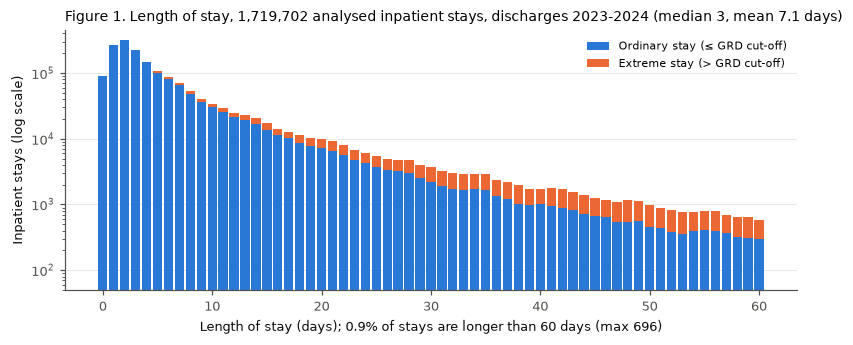

Share of outlier stays with LOS <= 10 days: 0.277 | inlier stays with LOS > 20 days: 68778


In [11]:
# Figure 1 · distribution: LOS by day, split into ordinary (inlier) and extreme (outlier) stays
cap = 60
v_in = A.loc[A.INLIER & (A.LOS <= cap), "LOS"].value_counts().reindex(range(cap+1), fill_value=0)
v_out = A.loc[A.OUTLIER & (A.LOS <= cap), "LOS"].value_counts().reindex(range(cap+1), fill_value=0)
fig, ax = plt.subplots(figsize=(7.4, 3.2))
ax.bar(v_in.index, v_in.values, color=BLUE, width=0.85, label="Ordinary stay (≤ GRD cut-off)")
ax.bar(v_out.index, v_out.values, bottom=v_in.values, color=ORANGE, width=0.85, label="Extreme stay (> GRD cut-off)")
ax.set_yscale("log"); ax.set_ylim(50, None)
ax.set_xlabel(f"Length of stay (days); {(A.LOS > cap).mean():.1%} of stays are longer than {cap} days (max {A.LOS.max():.0f})")
ax.set_ylabel("Inpatient stays (log scale)")
ax.set_title(f"Figure 1. Length of stay, {len(A):,} analysed inpatient stays, discharges 2023-2024 (median {A.LOS.median():.0f}, mean {A.LOS.mean():.1f} days)")
ax.legend(frameon=False, fontsize=7.5); ax.grid(axis="x", visible=False)
fig.tight_layout(); fig.savefig(FIG/"w2_fig1_los_distribution.png"); plt.show()
print("Share of outlier stays with LOS <= 10 days:", round(float((A.loc[A.OUTLIER, 'LOS'] <= 10).mean()), 3),
      "| inlier stays with LOS > 20 days:", int((A.INLIER & (A.LOS > 20)).sum()))

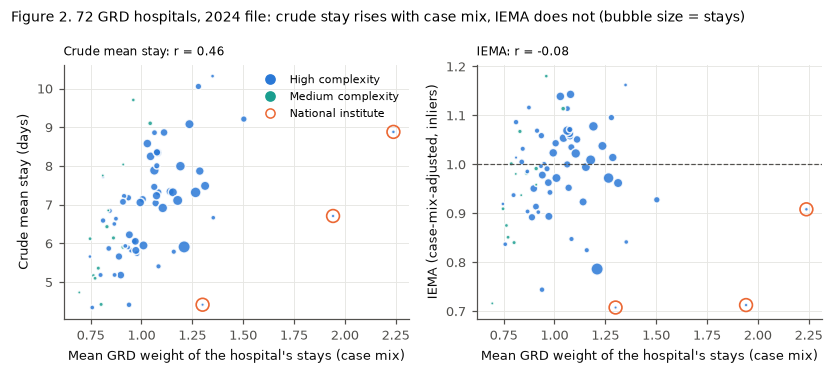

2024 classes: {'below network': 33, 'above network': 25, 'not distinguishable': 14} | institutes IEMA: [0.71, 0.91, 0.71]


In [12]:
# Figure 2 · relationship: crude stay vs case mix, and adjusted stay vs case mix, by hospital (2024 file)
H = hospital_kpis(A).join(A.groupby("HOSP")[["HOSPITAL", "COMPLEXITY", "INSTITUTE"]].first(), on="HOSP")
H24 = H.xs(2024, level="FILE_YEAR")
r_crude = H24[["crude_mean_los", "mean_weight"]].corr().iloc[0, 1]; r_iema = H24[["IEMA", "mean_weight"]].corr().iloc[0, 1]
colours = [BLUE if str(c).startswith("Alta") else TEAL for c in H24.COMPLEXITY]
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.6, 3.4), sharex=True)
for ax, col, ttl, r in ((a1, "crude_mean_los", "Crude mean stay (days)", r_crude), (a2, "IEMA", "IEMA (case-mix-adjusted, inliers)", r_iema)):
    ax.scatter(H24.mean_weight, H24[col], c=colours, s=H24.n/600, alpha=0.85, edgecolor="white")
    ax.scatter(H24.mean_weight[H24.INSTITUTE], H24[col][H24.INSTITUTE], facecolors="none", edgecolors=ORANGE, s=70, lw=1.1)
    ax.set_xlabel("Mean GRD weight of the hospital's stays (case mix)"); ax.set_ylabel(ttl); ax.set_title(f"{ttl.split(' (')[0]}: r = {r:.2f}", fontsize=8)
a2.axhline(1, color=INK2, lw=0.8, ls="--")
a1.legend(handles=[Line2D([], [], marker="o", ls="", color=BLUE, label="High complexity"), Line2D([], [], marker="o", ls="", color=TEAL, label="Medium complexity"),
                   Line2D([], [], marker="o", ls="", mfc="none", mec=ORANGE, label="National institute")], frameon=False, fontsize=7)
fig.suptitle("Figure 2. 72 GRD hospitals, 2024 file: crude stay rises with case mix, IEMA does not (bubble size = stays)", x=0.01, ha="left", fontsize=9)
fig.tight_layout(); fig.savefig(FIG/"w2_fig2_case_mix_relationship.png"); plt.show()
print("2024 classes:", H24["class"].value_counts().to_dict(), "| institutes IEMA:", H24.loc[H24.INSTITUTE, "IEMA"].round(2).tolist())

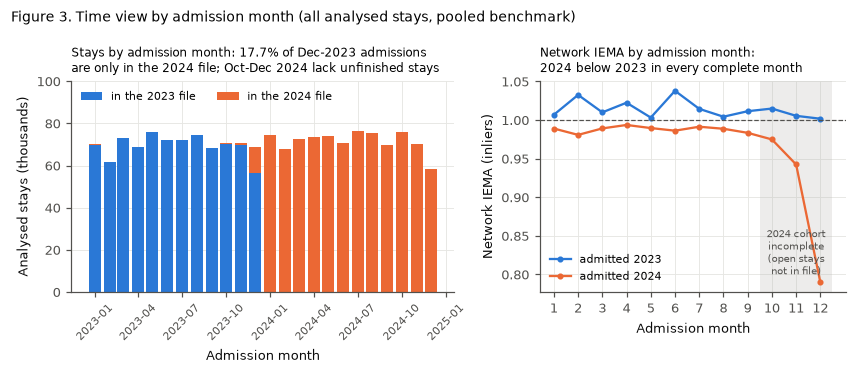

IEMA 2024 minus 2023 by admission month (Jan-Sep): [-0.018, -0.052, -0.021, -0.029, -0.014, -0.052, -0.023, -0.016, -0.028]
% of 2023 admissions found only in the 2024 file, by month: [0.02, 0.01, 0.02, 0.02, 0.03, 0.05, 0.1, 0.12, 0.23, 0.55, 1.74, 17.75]


In [13]:
# Figure 3 · over time: admissions by month and file, and network IEMA by admission month (the H4 test)
A["ADM_PERIOD"] = A.ADM.dt.to_period("M")
mm = A[A.ADM_YEAR >= 2023].groupby(["ADM_PERIOD", "FILE_YEAR"]).size().unstack(fill_value=0)
late = A[A.ADM_YEAR == 2023].groupby("ADM_MONTH").FILE_YEAR.apply(lambda s: (s == 2024).mean()*100)
cm = A[A.ADM_YEAR >= 2023].groupby(["ADM_YEAR", "ADM_MONTH"]).apply(
        lambda d: pd.Series({"IEMA": d.loc[d.INLIER, "LOS"].sum()/d.loc[d.INLIER, "EXPECTED"].sum(), "pct_outlier": d.OUTLIER.mean()*100,
                             "stays": len(d)}), include_groups=False).unstack(0)
fig, (a1, a2) = plt.subplots(1, 2, figsize=(7.8, 3.4), gridspec_kw={"width_ratios": [1.25, 1]})
x = mm.index.to_timestamp()
a1.bar(x, mm[2023]/1000, width=25, color=BLUE, label="in the 2023 file")
a1.bar(x, mm[2024]/1000, width=25, bottom=mm[2023]/1000, color=ORANGE, label="in the 2024 file")
a1.set_ylabel("Analysed stays (thousands)"); a1.set_xlabel("Admission month")
a1.set_title(f"Stays by admission month: {late.loc[12]:.1f}% of Dec-2023 admissions\nare only in the 2024 file; Oct-Dec 2024 lack unfinished stays", fontsize=8)
a1.set_ylim(0, 100); a1.legend(frameon=False, fontsize=7, loc="upper left", ncol=2); a1.tick_params(axis="x", labelrotation=45, labelsize=7)
months = range(1, 13)
a2.plot(months, cm[("IEMA", 2023)], color=BLUE, marker="o", ms=3, label="admitted 2023")
a2.plot(months, cm[("IEMA", 2024)], color=ORANGE, marker="o", ms=3, label="admitted 2024")
a2.axvspan(9.5, 12.5, color=GREY, alpha=0.25, lw=0)
a2.text(11, 0.86, "2024 cohort\nincomplete\n(open stays\nnot in file)", ha="center", va="top", fontsize=6.5, color=INK2)
a2.axhline(1, color=INK2, lw=0.8, ls="--"); a2.set_xticks(months); a2.set_xlabel("Admission month"); a2.set_ylabel("Network IEMA (inliers)")
a2.set_title("Network IEMA by admission month:\n2024 below 2023 in every complete month", fontsize=8); a2.legend(frameon=False, fontsize=7)
fig.suptitle("Figure 3. Time view by admission month (all analysed stays, pooled benchmark)", x=0.01, ha="left", fontsize=9)
fig.tight_layout(); fig.savefig(FIG/"w2_fig3_time_admission_cohorts.png"); plt.show()
gap = (cm[("IEMA", 2024)] - cm[("IEMA", 2023)]).loc[1:9]
print("IEMA 2024 minus 2023 by admission month (Jan-Sep):", gap.round(3).tolist())
print("% of 2023 admissions found only in the 2024 file, by month:", late.round(2).tolist())

In [14]:
# Segment view: extreme stays by admission type (denominator: analysed stays of each segment)
seg = A.groupby(A.TIPO_INGRESO.astype(str)).agg(stays=("LOS", "size"), pct_outlier=("OUTLIER", "mean"), mean_LOS=("LOS", "mean"),
                                                exp_outlier=("P_OUT", "mean"), bed_days=("LOS", "sum"))
seg["share_of_stays_%"] = seg.stays/len(A)*100; seg["pct_outlier"] *= 100
seg["observed/expected outliers"] = seg.pct_outlier/(seg.exp_outlier*100)
seg = seg.drop(columns="exp_outlier").sort_values("stays", ascending=False)
seg.to_csv(OUT/"w2_05_segment_admission_type.csv"); seg.round(3)

,stays,pct_outlier,mean_LOS,bed_days,share_of_stays_%,observed/expected outliers
TIPO_INGRESO,,,,,,
URGENCIA,1058473,7.510,9.146,9680714.0,61.550,1.192
PROGRAMADA,361702,3.088,4.225,1528138.0,21.033,0.452
OBSTETRICA,299429,6.840,3.208,960500.0,17.412,1.038
DESCONOCIDO,98,5.102,6.020,590.0,0.006,0.797


### 3.1 Interpretation

**Figure 1, distribution.**
- **Observation.** LOS is strongly right-skewed: median 3 days, mean 7.1, and 0.9% of stays last more than 60 days.
- "Extreme" is relative to the GRD, not a fixed length. 27.7% of extreme stays last 10 days or less (GRDs with short cut-offs), while 68,778 ordinary stays exceed 20 days.
- **What it does not show.** Why a stay is long, or which hospitals hold the tail.

**Figure 2, relationship.**
- **Observation.** Across hospitals, crude mean stay rises with case mix (r = 0.46). IEMA does not (r = −0.08), so the adjustment removes the case-mix effect it is designed to remove.
- The three national institutes have the heaviest case mix and IEMA below 1 (0.71, 0.71, 0.91).
- **What it does not show.** Efficiency against a clinical standard: the benchmark is the network itself. It also cannot reveal complexity that GRD does not capture, such as social discharge barriers.
- The pattern is an association across 72 hospitals, not a causal effect of any hospital practice.

**Figure 3, time (test of H4).**
- **Observation.** 17.7% of December-2023 admissions appear only in the 2024 file. Admissions in October-December 2024 lose their unfinished long stays, which is why their IEMA falls to 0.79 in December. These are artefacts of the file cut.
- In matched, complete cohorts the 2024 IEMA is still lower than 2023 in all nine months (gap −0.014 to −0.052), and in total: 0.988 vs 1.016.
- **H4 is rejected.** The C1 decrease is not caused by how the files are cut.
- **What it does not show.** Whether the decrease is real or comes from the shorter coding lag of the 2024 extraction (4.5 vs 8 months). The files cannot separate the two.

**Segment table (admission type).**
- **Observation.** Emergency admissions are 61.6% of stays and exceed their GRD cut-off more than the network rate for the same GRDs (observed/expected 1.19). Elective admissions do so far less (0.45).
- **Assumption.** This difference is treated as a signal worth testing at admission. It may reflect acuity within the same GRD rather than anything a hospital does.

**Denominators change C1 figures.**
- The share of bed-days in extreme stays is 25.4% in the 2024 discharge file but 24.1% in the January-September 2024 admission cohort, and 26.3% in the matching 2023 cohort.
- The 2024 file contains long stays begun in 2023, and the cohort lacks stays still open at the end of 2024.
- The C1 statement "about a quarter" holds, but every figure must now state its denominator (see section 7).

## 4. Sampling and representativeness (brief §4)

The data are not a sample drawn by us. They are a census of what FONASA published for the hospitals paid through GRD. Records enter through three selection mechanisms:
- the hospital is enrolled in GRD payment;
- the episode was coded by the extraction date;
- the discharge falls in the calendar year of the file.

Each mechanism is a possible source of bias.

In [15]:
pop = pd.DataFrame([
 ["Target population", "All inpatient stays in Chilean public hospitals, discharges 2023-2024, about which FONASA and Health Services make stay-review decisions", "not observed in full", "—"],
 ["Observed population", "GRD-coded episodes of the GRD-funded public hospitals, as present in FONASA's files at their extraction dates (04-09-2024 and 16-05-2025)",
  f"{len(g):,} episodes; {g.HOSP.nunique()} hospitals", "census of what FONASA published, not a random sample"],
 ["Analytical dataset", "Inpatient stays with valid dates and a benchmarkable GRD stratum (section 2)", f"{len(A):,} stays", "rule-based exclusions, all recorded"],
], columns=["level", "definition", "size", "how records were selected"])
cx = g.drop_duplicates("HOSP").COMPLEXITY.value_counts()
VS = g[g.EXCLUSION.isin(["", NB_REASON])]                     # all valid inpatient stays
adm_cut = VS[VS.ADM.dt.year == 2023].groupby(VS.ADM.dt.month).FILE_YEAR.apply(lambda s: (s == 2024).sum())
BIAS = pd.DataFrame([
 ["Hospital coverage (selection by payment mechanism)", f"Complexity of the {g.HOSP.nunique()} hospitals: {cx.to_dict()}; no low-complexity, private or armed-forces hospital",
  "Results describe high/medium-complexity public hospitals; LOS and case mix of excluded providers differ"],
 ["Discharge-year files (cohort truncation)", f"{(VS.ADM.dt.year < 2023).sum():,} stays in the 2023 file were admitted in 2022; {adm_cut.loc[12]:,} Dec-2023 admissions appear only in the 2024 file ({late.loc[12]:.1f}% of that month)",
  "Each file over-represents long stays that started the year before and misses stays still open on 31 December"],
 ["Extraction snapshot / coding lag", "2023 extracted 8 months after year end, 2024 only 4.5 months after; FONASA warns each file is a snapshot",
  "Late-coded or re-coded episodes of 2024 may be missing or different; cannot be measured from the files"],
 ["Change in hospital set", f"{len(set(A.HOSP[A.FILE_YEAR == 2024]) - set(A.HOSP[A.FILE_YEAR == 2023]))} hospitals enter in 2024 ({(A.FILE_YEAR.eq(2024) & ~A.HOSP.isin(COMMON)).sum():,} stays)",
  "Year comparisons must use the 68 common hospitals"],
], columns=["possible bias", "evidence in our data", "consequence"])
display(pop); BIAS

,level,definition,size,how records were selected
0,Target population,"All inpatient stays in Chilean public hospitals, discharges 2023-2024, about which FON...",not observed in full,—
1,Observed population,"GRD-coded episodes of the GRD-funded public hospitals, as present in FONASA's files at...","2,125,400 episodes; 72 hospitals","census of what FONASA published, not a random sample"
2,Analytical dataset,Inpatient stays with valid dates and a benchmarkable GRD stratum (section 2),"1,719,702 stays","rule-based exclusions, all recorded"


,possible bias,evidence in our data,consequence
0,Hospital coverage (selection by payment mechanism),"Complexity of the 72 hospitals: {'Alta Complejidad': 58, 'Mediana Complejidad': 14}; n...",Results describe high/medium-complexity public hospitals; LOS and case mix of excluded...
1,Discharge-year files (cohort truncation),"13,516 stays in the 2023 file were admitted in 2022; 12,184 Dec-2023 admissions appear...",Each file over-represents long stays that started the year before and misses stays sti...
2,Extraction snapshot / coding lag,"2023 extracted 8 months after year end, 2024 only 4.5 months after; FONASA warns each ...",Late-coded or re-coded episodes of 2024 may be missing or different; cannot be measure...
3,Change in hospital set,"4 hospitals enter in 2024 (16,393 stays)",Year comparisons must use the 68 common hospitals


In [16]:
# Reproducible 25% subsamples: simple random and stratified by hospital x file year
FRAC = 0.25
srs = A.sample(frac=FRAC, random_state=SEED)
strat = A.groupby(["HOSP", "FILE_YEAR"], group_keys=False).sample(frac=FRAC, random_state=SEED)
cols = ["stays", "mean_LOS", "%_stays_outlier", "%_bed_days_in_outliers", "network_IEMA", "%_emergency", "%_age_65+"]
cmp = pd.DataFrame({"full analysed dataset": kpis(A)[cols], "25% simple random (seed 2026)": kpis(srs)[cols],
                    "25% stratified hospital x year (seed 2026)": kpis(strat)[cols]})
cmp["SRS − full"] = cmp.iloc[:, 1] - cmp.iloc[:, 0]; cmp["stratified − full"] = cmp.iloc[:, 2] - cmp.iloc[:, 0]
cmp.loc["stays", ["SRS − full", "stratified − full"]] = np.nan
# sampling variability of the simple random design over 30 further seeds (derived from SEED)
rng = np.random.default_rng(SEED)
reps = pd.DataFrame([kpis(A.sample(frac=FRAC, random_state=int(s)))[cols[1:]] for s in rng.integers(0, 1_000_000, 30)])
cmp["SRS sd over 30 seeds"] = reps.std().reindex(cmp.index)
# hospital level: does a 25% sample reproduce hospital IEMA and classes? (2024 file)
Hs = hospital_kpis(srs).xs(2024, level="FILE_YEAR")
hj = H24[["IEMA", "class"]].join(Hs[["IEMA", "class"]], rsuffix="_sample")
HOSP_SAMPLE = {"spearman_IEMA_full_vs_sample": hj.IEMA.rank().corr(hj.IEMA_sample.rank()), "same_class": int((hj["class"] == hj.class_sample).sum()),
               "hospitals": len(hj), "not_distinguishable_full": int((hj["class"] == "not distinguishable").sum()),
               "not_distinguishable_sample": int((hj.class_sample == "not distinguishable").sum())}
cmp.to_csv(OUT/"w2_06_subsample_comparison.csv")
print(HOSP_SAMPLE); cmp.round(4)

{'spearman_IEMA_full_vs_sample': np.float64(0.9850472699208953), 'same_class': 68, 'hospitals': 72, 'not_distinguishable_full': 14, 'not_distinguishable_sample': 18}


C:\Users\tobal\AppData\Local\Temp\ipykernel_20400\3745590922.py:16: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  hj = H24[["IEMA", "class"]].join(Hs[["IEMA", "class"]], rsuffix="_sample")


,full analysed dataset,25% simple random (seed 2026),25% stratified hospital x year (seed 2026),SRS − full,stratified − full,SRS sd over 30 seeds
stays,1.719702e+06,429926.0000,429925.0000,NaN,NaN,NaN
mean_LOS,7.076800e+00,7.0754,7.1198,-0.0013,0.0430,0.0138
%_stays_outlier,6.463300e+00,6.4995,6.5046,0.0362,0.0414,0.0300
%_bed_days_in_outliers,2.583040e+01,25.8613,26.1685,0.0309,0.3381,0.1680
network_IEMA,9.997000e-01,0.9992,1.0008,-0.0006,0.0011,0.0015
%_emergency,6.154980e+01,61.6227,61.5686,0.0729,0.0189,0.0638
%_age_65+,2.689810e+01,26.8211,26.9128,-0.0770,0.0147,0.0504


### 4.1 Interpretation

**Observation.**
- A 25% simple random sample (seed 2026) reproduces the network KPIs of the analysed dataset within sampling error: differences of 0.04 percentage points in the outlier rate and 0.0006 in IEMA. Across 30 further seeds their standard deviations are 0.03 points and 0.0015.
- Stratifying by hospital and year does not help the bed-day share. It deviates by 0.34 points, about two standard deviations of the simple design, because that share is driven by a few very long stays, not by hospital mix.
- At hospital level a 25% sample keeps the ranking (Spearman 0.985), but 4 more hospitals become "not distinguishable" from the network (14 → 18). **Recommendation.** Hospital classification should use the full data, not a sample.

**What a subsample can and cannot show.**
- It reproduces the observed dataset, not the target population. It inherits every coverage bias in the table above: no low-complexity or private hospitals, truncated cohorts at both ends of each file, and coding up to the extraction date only.
- The same holds for a train/test split. A split only partitions the observed data. Agreement between train and test shows that a result is stable within the GRD network and period. It is no evidence that the network represents Chilean public hospitals as a whole, or that the 2024 snapshot represents the final 2024 coding.
- Representativeness can only be argued by comparing with an external source covering the target population, such as DEIS discharges from all facilities.

## 5. Leakage audit (brief §5)

**Decision time.**
- **Proposed predictive use (C1 continuity):** at **admission (t0)** a hospital flags stays at risk of exceeding their GRD cut-off, so discharge planning starts on day one.
- **Descriptive use (C1 dashboard):** decided once a year, after the FONASA extraction (t4). It has no predictive leakage problem, but the same timing rules apply if hospital indicators are ever used as model inputs.

The label (stay above the GRD cut-off) needs the GRD, which is assigned only after discharge (t3). That is legitimate for the **label**, but no input may come from t1-t4. A model would be built at a date **T = 2024-01-01**, using only labels known by then. The windows below are applied in section 6. The evidence table that follows is computed on **training rows only**.

In [17]:
T_CUT = pd.Timestamp("2024-01-01")       # date at which the model would be built; labels must be known by then
WINDOWS = pd.DataFrame([
 ["train", "admission 2023-01-01 to 2023-06-30", "discharged before 2024-01-01", "fit every learned parameter"],
 ["validation", "admission 2023-07-01 to 2023-09-30", "discharged before 2024-01-01", "choose features, thresholds, models (later stages)"],
 ["test", "admission 2024-01-01 to 2024-09-30", "any discharge in 2024", "one final evaluation only"],
 ["excluded", "admission before 2023, Oct-Dec 2023 (embargo), Oct-Dec 2024 (censored), or still in hospital on 2024-01-01", "—", "not used; counted"],
], columns=["subset", "admission window", "label condition", "use"])
FLOW = pd.DataFrame([
 ["t0 Admission (decision time)", "age, sex, insurance, admission type, origin, admitting unit, hospital, transfer-in hospital, date", "predict extreme-stay risk; start discharge planning"],
 ["t1 During stay", "operating theatre use (USOSPABELLON), internal moves", "not available at t0"],
 ["t2 Discharge", "discharge date, LOS, discharge type and unit", "label becomes measurable"],
 ["t3 Coding and grouping", "principal and secondary diagnoses, procedures, GRD code, weight, severity, mortality", "label rule (GRD cut-off) applicable"],
 ["t4 FONASA extraction (months later)", "file snapshot (2023: 04-09-2024; 2024: 16-05-2025)", "our data; annual descriptive review"],
], columns=["time point", "information that exists", "what can be decided"])
display(WINDOWS); FLOW

,subset,admission window,label condition,use
0,train,admission 2023-01-01 to 2023-06-30,discharged before 2024-01-01,fit every learned parameter
1,validation,admission 2023-07-01 to 2023-09-30,discharged before 2024-01-01,"choose features, thresholds, models (later stages)"
2,test,admission 2024-01-01 to 2024-09-30,any discharge in 2024,one final evaluation only
3,excluded,"admission before 2023, Oct-Dec 2023 (embargo), Oct-Dec 2024 (censored), or still in ho...",—,not used; counted


,time point,information that exists,what can be decided
0,t0 Admission (decision time),"age, sex, insurance, admission type, origin, admitting unit, hospital, transfer-in hos...",predict extreme-stay risk; start discharge planning
1,t1 During stay,"operating theatre use (USOSPABELLON), internal moves",not available at t0
2,t2 Discharge,"discharge date, LOS, discharge type and unit",label becomes measurable
3,t3 Coding and grouping,"principal and secondary diagnoses, procedures, GRD code, weight, severity, mortality",label rule (GRD cut-off) applicable
4,t4 FONASA extraction (months later),file snapshot (2023: 04-09-2024; 2024: 16-05-2025),our data; annual descriptive review


In [18]:
# Evidence for the leakage audit, computed on TRAINING rows only (admitted Jan-Jun 2023, discharged before T_CUT)
VALIDSET = g[g.EXCLUSION.isin(["", NB_REASON])]
TR = VALIDSET[(VALIDSET.ADM >= "2023-01-01") & (VALIDSET.ADM < "2023-07-01") & (VALIDSET.DIS < T_CUT)]
def spread(col, min_n=1000):
    t = TR.groupby(TR[col].astype(str)).LOS.agg(["size", "median", lambda s: (s > 30).mean()*100]); t.columns = ["n", "median", "pct_gt30"]
    t = t[t.n >= min_n]
    return {"categories (≥1000 rows)": len(t), "median LOS range": f"{t['median'].min():.0f}-{t['median'].max():.0f}",
            "% LOS > 30 d range": f"{t.pct_gt30.min():.1f}-{t.pct_gt30.max():.1f}"}
EVID = {}
for col, when in [("IR_29301_SEVERIDAD", "t3 coding"), ("TIPOALTA", "t2 discharge"), ("SERVICIOALTA", "t2 discharge"), ("USOSPABELLON", "t1 stay"),
                  ("TIPO_INGRESO", "t0 admission"), ("SERVICIOINGRESO", "t0 admission"), ("TIPO_PROCEDENCIA", "t0 admission"), ("ESPECIALIDAD_MEDICA", "uncertain")]:
    EVID[col] = {"available": when, **spread(col)}
for col, when in [("N_DIAG", "t3 coding"), ("N_PROC", "t3 coding"), ("WEIGHT", "t3 coding"), ("AGE", "t0 admission")]:
    EVID[col] = {"available": when, "Spearman rho with LOS": round(TR[[col, "LOS"]].corr(method="spearman").iloc[0, 1], 3)}
evid = pd.DataFrame(EVID).T
# Specialty: does it behave like the admitting or the discharge unit? (share of rows whose specialty label equals unit label)
sp, ui, uo = (TR[c].astype(str).str.upper().str.strip() for c in ["ESPECIALIDAD_MEDICA", "SERVICIOINGRESO", "SERVICIOALTA"])
SPEC = {"specialty = admitting unit label %": round(float((sp == ui).mean()*100), 2), "specialty = discharge unit label %": round(float((sp == uo).mean()*100), 2),
        "admitting unit = discharge unit %": round(float((ui == uo).mean()*100), 2)}
# Duplicates and repeated entities in the development window
DUP_TR = int(TR.duplicated(["FILE_YEAR", "ROWHASH"]).sum())
# Share of C1's benchmark reference rows that fall outside the training window (the C1 benchmark was fitted on all rows)
C1_REF_OUTSIDE_TRAIN = 1 - A.index.isin(TR.index).mean()
print("Training rows:", f"{len(TR):,}", "| exact duplicate rows inside train:", DUP_TR, "| specialty check:", SPEC)
print(f"Share of the C1 benchmark's reference rows outside the training window: {C1_REF_OUTSIDE_TRAIN:.1%}")
evid

Training rows: 421,352 | exact duplicate rows inside train: 21 | specialty check: {'specialty = admitting unit label %': 13.97, 'specialty = discharge unit label %': 14.82, 'admitting unit = discharge unit %': 83.07}
Share of the C1 benchmark's reference rows outside the training window: 75.5%


,available,categories (≥1000 rows),median LOS range,% LOS > 30 d range,Spearman rho with LOS
IR_29301_SEVERIDAD,t3 coding,3,2-7,0.8-9.9,NaN
TIPOALTA,t2 discharge,9,2-8,1.3-17.8,NaN
SERVICIOALTA,t2 discharge,48,1-18,0.0-25.1,NaN
USOSPABELLON,t1 stay,6,2-4,2.2-5.8,NaN
TIPO_INGRESO,t0 admission,3,2-5,0.3-5.2,NaN
SERVICIOINGRESO,t0 admission,52,1-16,0.0-31.7,NaN
TIPO_PROCEDENCIA,t0 admission,12,1-8,0.5-11.3,NaN
ESPECIALIDAD_MEDICA,uncertain,33,1-10,0.3-15.7,NaN
N_DIAG,t3 coding,NaN,NaN,NaN,0.435
N_PROC,t3 coding,NaN,NaN,NaN,0.549


### 5.1 Leakage risks, status and mitigation

| # | Risk (context-specific) | Status | Evidence in our data | Potential consequence | Mitigation (implemented unless stated) |
|---|---|---|---|---|---|
| L1 | Target-derived and post-admission fields: GRD, weight, severity, mortality, diagnoses, N_DIAG, N_PROC, theatre use, discharge type and unit, discharge date, LOS | **Present** in the data | Available only at t1-t3 (flow table). Strongly associated with LOS on training rows: Spearman ρ = 0.55 (N_PROC), 0.44 (N_DIAG), 0.33 (weight) vs 0.20 for age. The share of stays over 30 days ranges 0.8-9.9% across severity levels and 1.3-17.8% across discharge types | A model would look accurate but could not be used at admission | Excluded. Inputs are fixed in `ADM_FEATURES` (age, sex, insurance, admission type, origin, admitting unit, hospital, month, weekday, transfer-in) |
| L2 | Preprocessing learned from the whole dataset: the C1 GRD cut-offs that define the label | **Present** in C1 | The C1 benchmark was fitted on all 1,719,702 stays; 75.5% of them lie outside the training window, including the whole 2024 test period. Refitted on training rows, 65.8% of GRD codes get a different cut-off; 0.88% of validation labels change; validation prevalence moves from 6.63% (C1 rule) to 6.44% | Test labels partly built from test outcomes: optimistic, non-reproducible evaluation | Label rule refitted on training rows only (`FIT_BM`), applied unchanged to validation and test, parameter fingerprint checked before and after (section 6) |
| L3 | Future information through label maturity and file cut-off | **Present** | 17.7% of December-2023 admissions are discharged in 2024; 438 January-September 2023 admissions are still in hospital on 2024-01-01; IEMA of October-December 2024 admissions collapses (Figure 3) because open stays are missing | Training labels that could not be known at T; a test set biased toward short stays | Train/validation require discharge before T; October-December 2023 admissions excluded as an embargo; October-December 2024 excluded as right-censored; admissions before 2023 excluded as left-truncated; all counted in section 6 |
| L4 | Duplicated records | **Present within subsets, absent across** | 2,927 exact duplicate rows overall, 21 inside train; 0 row fingerprints shared between any two subsets (section 6) | Identical rows in train and test would inflate any score | The split is by admission date, so identical rows (same dates) always fall in the same subset; verified programmatically |
| L5 | Repeated patients (readmissions) | **Uncertain** | No patient identifier: it was dropped at extraction (data minimisation), and FONASA publishes no episode ID | Correlated patients across subsets; any prior-admission feature computed over the whole period would leak | No patient-history features in W2. If the encrypted patient ID is obtained: group by patient for diagnostics, and compute history only from admissions before t0 |
| L6 | Repeated hospitals and linked tables | **Present, managed** | The 68 hospitals of 2023 appear in every subset; 4 hospitals exist only in test (12,281 rows). C1 hospital IEMA and outlier rates were computed on 2023-2024, i.e. including the test period. The MINSAL facilities file is the current version, not the 2023 one | Hospital-level rates as inputs would carry test-period outcomes; complexity could be anachronistic | Hospital encoded with the training vocabulary only (unknown → `UNSEEN_HOSPITAL`); any hospital rate must be computed on training rows; complexity treated as static and flagged |
| L7 | Field with uncertain timing: `ESPECIALIDAD_MEDICA` | **Uncertain** | Its label equals the admitting-unit label in 14.0% of training rows and the discharge-unit label in 14.8%, so the data cannot tell when it is recorded | If assigned at discharge it would be an outcome-coded field | Excluded from inputs until FONASA documentation confirms its timing |
| L8 | Choices made with data from the evaluation period | **Present in C1, mitigated** | C1's EDA and its scan of admission fields used all 2023-2024 rows | Variables or thresholds tuned to the test period | W2 evidence on training rows only; the encoder threshold is chosen on validation (section 6); test prevalence is not computed. Residual limit: the team has already seen 2024 in C1, so the test set is not fully untouched |

**Assumption.** The "known at" column of the dictionary is our reading of FONASA's field definitions (admitting unit, origin and admission type recorded at admission). It has not been confirmed with FONASA.

## 6. Train, validation and test datasets (brief §6)

**Choice: chronological, by admission date, with an embargo.**
- **Business process.** The decision is made at admission, and a real model can only learn from stays already discharged and coded. A random split would train on 2024 outcomes to predict 2023 admissions.
- **Target.** The label depends on discharge and coding. Train and validation therefore keep only stays discharged before T, and the three months before T are left out because their labels were not yet mature (embargo).
- **Time ordering.** Test admissions are all after T. Train (January-June 2023) and validation (July-September 2023) are also ordered in time, so validation imitates the train-to-future step. Test (January-September 2024) covers the same calendar months as development, which keeps the seasonal mix comparable.
- **Repeated observations.** Hospitals repeat by design: the model would serve the same network. Patients cannot be grouped without an identifier (risk L5).
- **Proportions.** The result is about 33/17/51 rather than 80/20. Test is the largest share because every mature admission after T is kept, and 636,000 development stays are ample for the planned models.

In [19]:
P = VALIDSET.copy()   # all valid inpatient stays (incl. 16 not benchmarkable under C1): the label rule is refitted on train
P["SPLIT"] = "excluded: other"
adm, dis = P.ADM, P.DIS
P.loc[adm < "2023-01-01", "SPLIT"] = "excluded: admitted before 2023 (left-truncated)"
P.loc[(adm >= "2023-01-01") & (adm < "2023-07-01"), "SPLIT"] = "train"
P.loc[(adm >= "2023-07-01") & (adm < "2023-10-01"), "SPLIT"] = "validation"
P.loc[P.SPLIT.isin(["train", "validation"]) & (dis >= T_CUT), "SPLIT"] = "excluded: still in hospital on 2024-01-01 (label unknown at T)"
P.loc[(adm >= "2023-10-01") & (adm < T_CUT), "SPLIT"] = "excluded: admitted Oct-Dec 2023 (embargo)"
P.loc[(adm >= T_CUT) & (adm < "2024-10-01"), "SPLIT"] = "test"
P.loc[adm >= "2024-10-01", "SPLIT"] = "excluded: admitted Oct-Dec 2024 (right-censored)"
assert (P.SPLIT == "excluded: other").sum() == 0
sc = P.groupby("SPLIT").agg(rows=("LOS", "size"), adm_min=("ADM", "min"), adm_max=("ADM", "max"), dis_min=("DIS", "min"), dis_max=("DIS", "max"),
                            hospitals=("HOSP", "nunique"), from_2023_file=("FILE_YEAR", lambda s: int((s == 2023).sum())),
                            from_2024_file=("FILE_YEAR", lambda s: int((s == 2024).sum())))
sc["% of valid stays"] = sc.rows/len(P)*100
usable = sc.loc[["train", "validation", "test"], "rows"]; sc["% of train+validation+test"] = (usable/usable.sum()*100).reindex(sc.index)
sc = sc.loc[["train", "validation", "test"] + sorted(i for i in sc.index if i.startswith("excluded"))]
assert sc.rows.sum() == len(P)
sc.to_csv(OUT/"w2_07_split_counts.csv"); sc

,rows,adm_min,adm_max,dis_min,dis_max,hospitals,from_2023_file,from_2024_file,% of valid stays,% of train+validation+test
SPLIT,,,,,,,,,,
train,421352,2023-01-01,2023-06-30,2023-01-01,2023-12-29,68,421352,0,24.501226,32.629734
validation,214640,2023-07-01,2023-09-30,2023-07-01,2023-12-31,68,214640,0,12.481116,16.621841
test,655321,2024-01-01,2024-09-30,2024-01-01,2024-12-31,72,0,655321,38.106306,50.748424
excluded: admitted Oct-Dec 2023 (embargo),210310,2023-10-01,2023-12-31,2023-10-01,2024-12-21,72,196505,13805,12.229331,NaN
excluded: admitted Oct-Dec 2024 (right-censored),204141,2024-10-01,2024-12-31,2024-10-01,2024-12-31,72,0,204141,11.870609,NaN
excluded: admitted before 2023 (left-truncated),13516,2022-01-07,2022-12-31,2023-01-01,2023-12-28,68,13516,0,0.785943,NaN
excluded: still in hospital on 2024-01-01 (label unknown at T),438,2023-01-01,2023-09-30,2024-01-02,2024-12-30,62,0,438,0.025469,NaN


In [20]:
# Overlap and leakage verification between the three subsets
S = {k: P[P.SPLIT == k] for k in ("train", "validation", "test")}
ver = []
def v(name, ok, detail): ver.append({"verification": name, "result": "OK" if ok else "ATTENTION", "detail": detail})
v("Every valid stay assigned to exactly one subset", P.SPLIT.notna().all() and sc.rows.sum() == len(P), f"{len(P):,} rows")
v("Admission windows do not overlap", S["train"].ADM.max() < S["validation"].ADM.min() and S["validation"].ADM.max() < S["test"].ADM.min(),
  f"train ≤ {S['train'].ADM.max().date()} < validation ≥ {S['validation'].ADM.min().date()}; validation ≤ {S['validation'].ADM.max().date()} < test ≥ {S['test'].ADM.min().date()}")
v("Train and validation labels known before T (2024-01-01)", max(S["train"].DIS.max(), S["validation"].DIS.max()) < T_CUT,
  f"latest discharge {max(S['train'].DIS.max(), S['validation'].DIS.max()).date()}")
for a_, b_ in (("train", "validation"), ("train", "test"), ("validation", "test")):
    n = len(set(S[a_].ROWHASH) & set(S[b_].ROWHASH))
    v(f"Identical source rows shared by {a_} and {b_}", n == 0, f"{n} shared row fingerprints")
new_h = sorted(set(S["test"].HOSP) - set(S["train"].HOSP))
v("Hospitals in test absent from train (expected: hospitals new in 2024)", True,
  f"{len(new_h)} hospitals, {S['test'].HOSP.isin(new_h).sum():,} test rows: {', '.join(S['test'][S['test'].HOSP.isin(new_h)].HOSPITAL.unique())}")
v("Repeated patients across subsets", False, "cannot be verified: no patient identifier in the extract (flagged limitation)")
ver = pd.DataFrame(ver); ver.to_csv(OUT/"w2_08_split_verification.csv", index=False); ver

,verification,result,detail
0,Every valid stay assigned to exactly one subset,OK,"1,719,718 rows"
1,Admission windows do not overlap,OK,train ≤ 2023-06-30 < validation ≥ 2023-07-01; validation ≤ 2023-09-30 < test ≥ 2024-01-01
2,Train and validation labels known before T (2024-01-01),OK,latest discharge 2023-12-31
3,Identical source rows shared by train and validation,OK,0 shared row fingerprints
4,Identical source rows shared by train and test,OK,0 shared row fingerprints
5,Identical source rows shared by validation and test,OK,0 shared row fingerprints
6,Hospitals in test absent from train (expected: hospitals new in 2024),OK,"4 hospitals, 12,281 test rows: Hospital Penco Lirquén, Hospital San Juan de Dios (Cauq..."
7,Repeated patients across subsets,ATTENTION,cannot be verified: no patient identifier in the extract (flagged limitation)


### 6.1 Train-only fitted preprocessing

Four parameters are learned from the **training subset only** and stored in `w2_10_train_fitted_parameters.csv` and `w2_09_train_benchmark_by_grd.csv`:

1. **Label rule.** GRD cut-off and expected LOS per code, with the C1 fallback to base GRD. A code not seen in training uses its base GRD learned in training, or gets no label.
2. **Imputation value.** The median age, for the few rows without age.
3. **Admitting-unit encoder vocabulary.** Units with fewer training rows than a threshold become `OTHER`. The threshold is **chosen on the validation subset**: the fewest units that keep at most 2% of validation rows in `OTHER`. This is a small example of the validation subset doing its job without touching test.
4. **Hospital vocabulary.** A hospital not seen in training becomes `UNSEEN_HOSPITAL`.

The transform step only applies these rules. A fingerprint of the fitted parameters is recomputed after transforming validation and test to prove nothing was refitted. Label prevalence is reported for train and validation but **deliberately not computed for test**.

In [21]:
# FIT: every parameter below is learned from the training subset only
train = S["train"]
FIT_BM = build_benchmark(train)                                    # (1) label rule: cut-off and expected LOS per GRD
AGE_MEDIAN = float(train.AGE.median())                             # (2) imputation value for missing age
def params_fingerprint():
    blob = FIT_BM[["CUT", "EXPECTED"]].to_csv() + FIT_BM.attrs["base"].to_csv() + str(AGE_MEDIAN)
    return hashlib.sha256(blob.encode()).hexdigest()[:16]
FP_BEFORE = params_fingerprint()

# Validation is used to choose the rare-category threshold of the admitting-unit encoder (test is not involved)
unit_counts_train = train.SERVICIOINGRESO.astype(str).value_counts()
choice = []
for thr in (50, 200, 500, 2000, 5000):
    vocab = set(unit_counts_train[unit_counts_train >= thr].index)
    choice.append({"min train rows per unit": thr, "units kept": len(vocab),
                   "validation rows mapped to OTHER %": round(float((~S["validation"].SERVICIOINGRESO.astype(str).isin(vocab)).mean()*100), 3)})
choice = pd.DataFrame(choice)
UNIT_MIN = int(choice.loc[choice["validation rows mapped to OTHER %"] <= 2.0, "min train rows per unit"].max())   # rule: fewest units with ≤ 2% of validation in OTHER
UNIT_VOCAB = sorted(unit_counts_train[unit_counts_train >= UNIT_MIN].index)                                   # (3) encoder vocabulary
HOSP_VOCAB = sorted(train.HOSP.unique())                                                                      # (4) hospital vocabulary
print("Fingerprint of fitted parameters:", FP_BEFORE, "| age median (train):", AGE_MEDIAN, "| unit threshold chosen on validation:", UNIT_MIN,
      "| units kept:", len(UNIT_VOCAB))
FIT_BM.assign(DESCRIPTION=GRD_DESC.reindex(FIT_BM.index).values).to_csv(OUT/"w2_09_train_benchmark_by_grd.csv")
pd.Series({"AGE_MEDIAN": AGE_MEDIAN, "UNIT_MIN": UNIT_MIN, "UNIT_VOCAB": "|".join(UNIT_VOCAB), "HOSP_VOCAB": "|".join(HOSP_VOCAB),
           "fingerprint": FP_BEFORE}).to_csv(OUT/"w2_10_train_fitted_parameters.csv", header=["value"])
choice

Fingerprint of fitted parameters: 74df5f80e29cb902 | age median (train): 40.0 | unit threshold chosen on validation: 500 | units kept: 65


,min train rows per unit,units kept,validation rows mapped to OTHER %
0,50,79,0.024
1,200,73,0.227
2,500,65,0.906
3,2000,40,7.308
4,5000,23,20.330


In [22]:
# TRANSFORM: apply the learned rules to each subset without refitting
ADM_FEATURES = ["AGE", "SEXO", "PREVISION", "TIPO_INGRESO", "TIPO_PROCEDENCIA", "UNIT", "HOSP_ENC", "ADM_MONTH", "ADM_WEEKDAY", "TRANSFER_IN"]
def transform(d):
    d = apply_benchmark(d.drop(columns=[c for c in ["CUT", "EXPECTED", "P_OUT", "LEVEL", "BENCH", "OUTLIER", "INLIER"] if c in d]), FIT_BM, use_base_for_unseen=True)
    d["LABEL"] = d.OUTLIER.where(d.BENCH).astype("boolean")                     # target: stay above the train-learned GRD cut-off
    d["AGE_IMPUTED"] = d.AGE.isna(); d["AGE"] = d.AGE.fillna(AGE_MEDIAN)
    d["UNIT"] = d.SERVICIOINGRESO.astype(str).where(d.SERVICIOINGRESO.astype(str).isin(UNIT_VOCAB), "OTHER")
    d["HOSP_ENC"] = d.HOSP.where(d.HOSP.isin(HOSP_VOCAB), "UNSEEN_HOSPITAL")
    d["ADM_MONTH"], d["ADM_WEEKDAY"] = d.ADM.dt.month, d.ADM.dt.dayofweek
    d["TRANSFER_IN"] = d.HOSPPROCEDENCIA.astype(str).str.strip() != ""
    return d
Z = {k: transform(v_) for k, v_ in S.items()}
assert params_fingerprint() == FP_BEFORE, "a fitted parameter changed during transform"
tr = []
for k, d in Z.items():
    tr.append({"subset": k, "rows": len(d), "label available": int(d.LABEL.notna().sum()), "no benchmark (unseen GRD, no base)": int(d.LABEL.isna().sum()),
               "GRD code unseen in train (base rule used)": int((d.LEVEL == "unseen code: base GRD").sum()),
               "age imputed": int(d.AGE_IMPUTED.sum()), "unit → OTHER %": round(float((d.UNIT == "OTHER").mean()*100), 3),
               "hospital unseen": int((d.HOSP_ENC == "UNSEEN_HOSPITAL").sum()),
               "label prevalence %": round(float(d.LABEL.mean()*100), 3) if k != "test" else "not computed (test)"})
tr = pd.DataFrame(tr).set_index("subset"); tr.to_csv(OUT/"w2_11_transform_report.csv")
print("Fingerprint after transforming validation and test:", params_fingerprint(), "(unchanged)")
tr

C:\Users\tobal\AppData\Local\Temp\ipykernel_20400\2958435054.py:9: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d["ADM_MONTH"], d["ADM_WEEKDAY"] = d.ADM.dt.month, d.ADM.dt.dayofweek
C:\Users\tobal\AppData\Local\Temp\ipykernel_20400\2958435054.py:9: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d["ADM_MONTH"], d["ADM_WEEKDAY"] = d.ADM.dt.month, d.ADM.dt.dayofweek
C:\Users\tobal\AppData\Local\Temp\ipykernel_20400\2958435054.py:9: Pandas4Warning: Series.dt.dayofweek is deprecated and will be removed in a future version. Use Series.dt.day_of_week instead.
  d["ADM_MONTH"], d["ADM_WEEKDAY"] = d.ADM.dt.month, d.ADM.dt.dayofweek


Fingerprint after transforming validation and test: 74df5f80e29cb902 (unchanged)


,rows,label available,"no benchmark (unseen GRD, no base)",GRD code unseen in train (base rule used),age imputed,unit → OTHER %,hospital unseen,label prevalence %
subset,,,,,,,,
train,421352,421226,126,0,6,0.825,0,6.305
validation,214640,214565,75,5,0,0.906,0,6.442
test,655321,655093,228,9,1,1.013,12281,not computed (test)


In [23]:
# Why train-only fitting matters, shown on the validation subset: C1's pooled cut-offs (fitted on all 2023-2024 rows) vs train-only cut-offs
vz = Z["validation"].join(c1_bm[["CUT"]].rename(columns={"CUT": "CUT_C1"}), on="GRD")
vz["LABEL_C1"] = vz.LOS > vz.CUT_C1
both = vz[vz.LABEL.notna() & vz.CUT_C1.notna()]
cut_cmp = FIT_BM[["CUT"]].join(c1_bm[["CUT"]], rsuffix="_C1", how="inner").dropna()
LEAK_DEMO = {"validation rows compared": len(both), "label differs (C1 pooled vs train-only) %": round(float((both.LABEL.astype(bool) != both.LABEL_C1).mean()*100), 3),
             "validation prevalence, train-only rule %": round(float(both.LABEL.astype(bool).mean()*100), 3),
             "validation prevalence, C1 pooled rule %": round(float(both.LABEL_C1.mean()*100), 3),
             "GRD codes with a different cut-off %": round(float((cut_cmp.CUT != cut_cmp.CUT_C1).mean()*100), 1)}
X = {k: d[ADM_FEATURES] for k, d in Z.items()}; Y = {k: d.LABEL for k, d in Z.items()}
print({k: x.shape for k, x in X.items()}); pd.Series(LEAK_DEMO)

{'train': (421352, 10), 'validation': (214640, 10), 'test': (655321, 10)}


C:\Users\tobal\AppData\Local\Temp\ipykernel_20400\3365557094.py:5: Pandas4Warning: The 'lsuffix' and 'rsuffix' keywords in DataFrame.join are deprecated and will be removed in a future version. Use the 'suffixes' keyword instead.
  cut_cmp = FIT_BM[["CUT"]].join(c1_bm[["CUT"]], rsuffix="_C1", how="inner").dropna()


validation rows compared                     214565.000
label differs (C1 pooled vs train-only) %         0.882
validation prevalence, train-only rule %          6.442
validation prevalence, C1 pooled rule %           6.633
GRD codes with a different cut-off %             65.800
dtype: float64

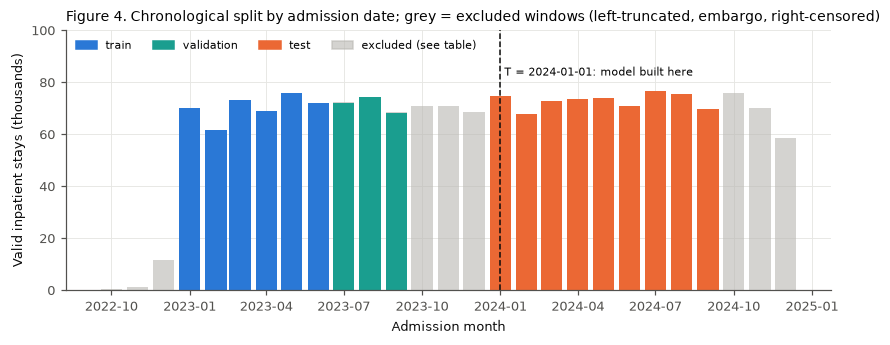

In [24]:
# Figure 4 · the split on the admission timeline
sp_m = P.assign(M=P.ADM.dt.to_period("M")).groupby(["M", "SPLIT"]).size().unstack(fill_value=0)
sp_m = sp_m[sp_m.index >= pd.Period("2022-10", "M")]
order = ["train", "validation", "test"] + [c for c in sp_m.columns if c.startswith("excluded")]
COL = {"train": BLUE, "validation": TEAL, "test": ORANGE}
fig, ax = plt.subplots(figsize=(7.8, 3.2)); bottom = np.zeros(len(sp_m)); x = sp_m.index.to_timestamp()
for c in order:
    if c in sp_m:
        ax.bar(x, sp_m[c]/1000, width=25, bottom=bottom, color=COL.get(c, GREY), alpha=1 if c in COL else 0.6, label=c if c in COL else None); bottom += sp_m[c].values/1000
ax.set_ylim(0, 100); ax.axvline(T_CUT, color=INK, lw=1, ls="--"); ax.text(T_CUT, 86, " T = 2024-01-01: model built here", fontsize=7, va="top", ha="left")
ax.legend(handles=[Patch(color=BLUE, label="train"), Patch(color=TEAL, label="validation"), Patch(color=ORANGE, label="test"), Patch(color=GREY, alpha=0.6, label="excluded (see table)")],
          frameon=False, fontsize=7, ncol=4, loc="upper left")
ax.set_ylabel("Valid inpatient stays (thousands)"); ax.set_xlabel("Admission month")
ax.set_title("Figure 4. Chronological split by admission date; grey = excluded windows (left-truncated, embargo, right-censored)")
fig.tight_layout(); fig.savefig(FIG/"w2_fig4_split_timeline.png"); plt.show()

### 6.2 Validation plan and treatment of the test set

| Subset | Admissions | Rows | Used for | Never used for |
|---|---|---|---|---|
| Train | January-June 2023, discharged before T | 421,352 | Fitting every parameter: label rule, imputation, encoders, and model weights in the next stage | — |
| Validation | July-September 2023, discharged before T | 214,640 | Choosing variables, thresholds and models. Already used here for the encoder threshold. Optional extension: rolling-origin folds inside January-September 2023 | Fitting the label rule |
| Test | January-September 2024 | 655,321 | One final evaluation of the chosen pipeline, after refitting all parameters on train + validation only | Any choice: variables, cleaning thresholds, tuning, or even looking at prevalence |

**Implemented in W2:** the three subsets with counts and proportions, six verifications (no date overlap, labels known before T, 0 shared rows), the train-only fit with fingerprint, the validation-based choice of the encoder threshold, and the admission-time input matrices `X` and labels `Y`. No model is fitted and no metric is reported, as the brief requires.

**Limits of the holdout.**
- The 2024 period was explored in W1 and C1 (descriptive EDA, the 0.93 correlation between years), and section 3 of this notebook uses all years descriptively. The test set is therefore **not untouched** in the sense of never having been seen. What is guaranteed is that no parameter, variable choice or threshold in this notebook was learned from it.
- For the descriptive findings (hospital IEMA classes), the 2024 file acts as an independent robustness check of 2023, not as a measure of predictive accuracy.
- The test set lacks October-December 2024 and four hospitals have no training history, so results on it describe a nine-month horizon in the same network.

## 7. Revised conclusions, management summary and AI-use disclosure

**Hypotheses, resolved.**
- **H1 is supported.** It is unchanged from C1, and Figure 2 confirms the adjustment works.
- **H2 is supported with a qualification:** extreme stays hold 24.1-26.3% of bed-days, depending on the denominator.
- **H3 is rejected.** The institutes are below the network.
- **H4 is rejected.** The 2024 decrease is not produced by how the files are cut.
- **H5 is supported as a design:** a split, label rule and inputs without detected leakage exist. Its predictive value is untested.

The table below lists each W1/C1 statement that changes, with its evidence.

In [25]:
c1_kpi = pd.read_csv(C1/"data/processed/c1_09_network_summary.csv", index_col=0)
REV = pd.DataFrame([
 ["Network IEMA is lower in 2024 (0.987 vs 1.013); unresolved whether real or an extraction-lag effect (C1 reflection)",
  f"Same gap in matched admission cohorts Jan-Sep: {desc.loc['Admitted Jan-Sep 2023 (both files)', 'network_IEMA']:.3f} vs {desc.loc['Admitted Jan-Sep 2024', 'network_IEMA']:.3f}; 2024 lower in all 9 months (Figure 3)",
  "Narrowed: the gap is not caused by how files are cut by discharge year. Coding lag or a real change remain possible"],
 ["Extreme stays hold 25.4% of bed-days in 2024 (2024 discharge file)",
  f"{desc.loc['Admitted Jan-Sep 2024', '%_bed_days_in_outliers']:.1f}% for 2024 admissions Jan-Sep vs {desc.loc['Admitted Jan-Sep 2023 (both files)', '%_bed_days_in_outliers']:.1f}% for the 2023 cohort",
  "Qualified: the share depends on the denominator (discharge file vs admission cohort); the 2024 file includes long stays begun in 2023. Always state the denominator"],
 ["ML label prevalence ≈ 6.3%, stable (C1 continuity section)",
  f"With the label rule refitted on training rows: train {tr.loc['train', 'label prevalence %']:.2f}%, validation {tr.loc['validation', 'label prevalence %']:.2f}%",
  "Corrected: the C1 figure used a benchmark fitted on all rows; the prevalence quoted for prediction is now train-based"],
 ["Admission-time fields vary with extreme stays (C1 univariate scan on all 2023-2024 rows)",
  "Re-examined on training rows only (leakage evidence table); test rows were not used to select variables",
  "Method corrected: C1's scan used the future test period; conclusions kept as a hypothesis for the next stage"],
 ["National institutes would have longer adjusted stay (W1 hypothesis)",
  f"IEMA 2024 of the three institutes: {', '.join(f'{x:.2f}' for x in H24.loc[H24.INSTITUTE, 'IEMA'])}",
  "Rejected (already in C1); now stated explicitly as a changed conclusion"],
], columns=["W1/C1 statement", "W2 evidence", "change"])
REV.to_csv(OUT/"w2_12_revised_conclusions.csv", index=False); REV

,W1/C1 statement,W2 evidence,change
0,Network IEMA is lower in 2024 (0.987 vs 1.013); unresolved whether real or an extracti...,Same gap in matched admission cohorts Jan-Sep: 1.016 vs 0.988; 2024 lower in all 9 mon...,Narrowed: the gap is not caused by how files are cut by discharge year. Coding lag or ...
1,Extreme stays hold 25.4% of bed-days in 2024 (2024 discharge file),24.1% for 2024 admissions Jan-Sep vs 26.3% for the 2023 cohort,Qualified: the share depends on the denominator (discharge file vs admission cohort); ...
2,"ML label prevalence ≈ 6.3%, stable (C1 continuity section)","With the label rule refitted on training rows: train 6.30%, validation 6.44%",Corrected: the C1 figure used a benchmark fitted on all rows; the prevalence quoted fo...
3,Admission-time fields vary with extreme stays (C1 univariate scan on all 2023-2024 rows),Re-examined on training rows only (leakage evidence table); test rows were not used to...,Method corrected: C1's scan used the future test period; conclusions kept as a hypothe...
4,National institutes would have longer adjusted stay (W1 hypothesis),"IEMA 2024 of the three institutes: 0.71, 0.91, 0.71",Rejected (already in C1); now stated explicitly as a changed conclusion


In [26]:
# Packaging check (C1 feedback: README named incorrectly; paths and packaging)
pk = []
for stage in ("GROUP_01_C1", "GROUP_01_W2"):
    misnamed = [p.name for p in (REPO/stage).glob("README*") if p.name != "README.md"]
    pk.append({"check": f"{stage}/README.md exists with the exact name", "ok": (REPO/stage/"README.md").exists() and not misnamed,
               "detail": f"other README-like files: {misnamed or 'none'}"})
for f in ["README.md", "requirements.txt", "notebooks/W2_project.ipynb"]:
    pk.append({"check": f"GROUP_01_W2/{f} present", "ok": (BASE/f).exists(), "detail": ""})
pk.append({"check": "all outputs written inside GROUP_01_W2/data", "ok": all(BASE in p.parents for p in list(OUT.glob("w2_*")) + list(FIG.glob("w2_*"))),
           "detail": f"{len(list(OUT.glob('w2_*')))} tables, {len(list(FIG.glob('w2_*')))} figures"})
pk = pd.DataFrame(pk); display(pk)
assert pk.ok.all(), "packaging check failed"
for p in sorted(OUT.glob("w2_*")) + sorted(FIG.glob("w2_*")): print(p.relative_to(BASE))

,check,ok,detail
0,GROUP_01_C1/README.md exists with the exact name,True,other README-like files: none
1,GROUP_01_W2/README.md exists with the exact name,True,other README-like files: none
2,GROUP_01_W2/README.md present,True,
3,GROUP_01_W2/requirements.txt present,True,
4,GROUP_01_W2/notebooks/W2_project.ipynb present,True,
5,all outputs written inside GROUP_01_W2/data,True,"14 tables, 4 figures"


data\processed\w2_00_input_files.csv
data\processed\w2_01_data_dictionary.csv
data\processed\w2_02_validation_checks.csv
data\processed\w2_03_row_flow.csv
data\processed\w2_03b_exclusions_by_reason.csv
data\processed\w2_04_descriptive_kpis.csv
data\processed\w2_05_segment_admission_type.csv
data\processed\w2_06_subsample_comparison.csv
data\processed\w2_07_split_counts.csv
data\processed\w2_08_split_verification.csv
data\processed\w2_09_train_benchmark_by_grd.csv
data\processed\w2_10_train_fitted_parameters.csv
data\processed\w2_11_transform_report.csv
data\processed\w2_12_revised_conclusions.csv
data\figures\w2_fig1_los_distribution.png
data\figures\w2_fig2_case_mix_relationship.png
data\figures\w2_fig3_time_admission_cohorts.png
data\figures\w2_fig4_split_timeline.png


### 7.1 Management summary

W2 keeps the C1 question and KPIs (case-mix-adjusted stay, IEMA, and the share of bed-days in extreme stays) and strengthens how they are measured and validated. Twenty-one programmatic checks confirm the C1 inputs and reproduce its benchmark exactly; every excluded row carries a recorded reason. Two C1 statements changed. The lower network IEMA in 2024 is not an artefact of discharge-year files: it persists in matched admission cohorts (0.988 vs 1.016) in every month, so coding lag or a real change remain the explanations. The extreme-stay share of bed-days depends on the denominator (24.1% to 26.3%). For the proposed admission-time classifier, the C1 benchmark had been fitted on all data, including the future test period; W2 refits it on training admissions only, excludes discharge-time fields and builds a chronological split (421,352 / 214,640 / 655,321 stays) with verified separation. Repeated patients remain unverifiable. Next step: obtain the encrypted patient identifier and the ministerial norm, then compare baseline models on validation only.

**Recommendation.** Use IEMA classes, not rankings, to choose where to start stay reviews; always report extreme-stay shares with their denominator; do not use any 2024 outcome to design the future model.

### 7.2 AI-use disclosure

Claude (Anthropic), in a claude.ai Project chat on 23-10-2026, read the W2 brief, the W1 and C1 packages, and reviewed this notebook's code and text. The team supplied the project history, the W1 grade and feedback, and the informal C1 feedback. The AI proposed the admission-date split with embargo, the train-only refit of the benchmark and the leakage register, the team accepted the AI's proposals.

All figures were verified by re-running the notebook.

The team is responsible for every result and methodological choice in this notebook.